# Does segmentation help food classification? — dataset `03_denoise_clahe_gsam`

**Question.** Does removing the background (Grounded-SAM) before classification improve accuracy on 10 Food-101 classes?
The same notebook runs on all three datasets, so every dataset gets exactly the same pipeline. Only `DATASET` changes:

| dataset | preprocessing |
|---|---|
| `01_original` | resized originals (baseline) |
| `02_denoise_clahe` | 01 + wavelet denoise (BayesShrink) + CLAHE on the L channel of LAB |
| `03_denoise_clahe_gsam` | 02 + Grounded-SAM: food kept, background grey (124,116,104), cropped to the food |

**Data.** 10 classes × (578 train / 193 val / 192 test) = 9,630 images. Wrong-label, non-food and duplicate images were already removed (`meta/removed.csv`),
and every class was cut to the same size, then split 60/20/20 with seed 42. **Never re-split**: the folders are the split.

**Models** (same architecture and the same tuning grid on every dataset, see 0.1):

| # | model | what is tuned (on val only) | train/val graph |
|---|---|---|---|
| 1 | CLIP ViT-B/32 zero-shot (baseline) | prompt template | val score per template (nothing is trained) |
| 2 | Classical: handcrafted features → Logistic Regression / SVM (RBF) | `C`, `gamma` | validation curve over `C` |
| 3 | CNN from scratch | depth (number of conv blocks), epochs (early stopping) | learning curves + train/val vs depth |
| 4 | ResNet-50 transfer (ImageNet) | how much to unfreeze (`fc` / `layer4` / `all`), epochs | learning curves + train/val vs unfreeze level |

**Metrics.** top-1 / top-3 / top-5 accuracy, macro precision / recall / F1, per-class AP and mAP, 10×10 confusion matrix,
correct and wrong test examples, Grad-CAM. Model selection uses **val macro-F1**; the test set is scored once per model, at the end.

### How to run
- **VS Code (local, Apple M1 → MPS):** put the zip contents in `data/dataset/` (so `data/dataset/03_denoise_clahe_gsam/` and `data/dataset/meta/` exist),
  install the kernel once with `.venv/bin/pip install ipykernel`, pick `.venv` as the kernel, *Run All*.
- **Colab (GPU):** *Runtime → Change runtime type → T4 GPU*. Upload `03_denoise_clahe_gsam.zip` to `MyDrive/food_classify/`. *Run All* (it mounts Drive and unzips).
- First run `RUN_MODE = "smoke"` (20 images per class, 2 epochs, ~15 min plus a one-time ~700 MB download of CLIP and ResNet-50 weights) to check that every cell works, then `RUN_MODE = "full"`.
- Trained models, histories and results are saved; re-running a cell loads them instead of training again (`RETRAIN = True` to force).

Rough full-run time: M1 ≈ 3–4 h (CNN ≈ 1.5 h, ResNet-50 ≈ 1.5 h, SVM grid ≈ 15 min), Colab T4 ≈ 1 h.

## 0. Configuration

### 0.1 Fair-comparison rules used here
1. **Same architecture and same search space** for a model on 01 / 02 / 03 (the grids below). Each dataset may pick its own best value from that grid,
   chosen by val macro-F1 with the same early-stopping rule. Same budget, same rule, so differences come from the data, not from extra tuning.
2. **Same input pipeline everywhere:** pad to square with the grey fill → resize to 224×224 → ImageNet normalisation (CLIP uses its own mean/std).
   Padding instead of center-crop because 30% of the GSAM crops are wider than 4:3 and a center crop would cut food off.
3. **No colour jitter** in augmentation, because colour and contrast are what dataset 02 changes. Augmentation is only a mild random crop + horizontal flip, on train only.
4. Same seed, same split. Test is never used to choose anything.

In [1]:
# ==== the only cell you normally edit ====
DATASET = "03_denoise_clahe_gsam"   # "01_original" | "02_denoise_clahe" | "03_denoise_clahe_gsam"
RUN_MODE = "full"                  # "smoke": 20 imgs/class/split, 2 epochs, to test the pipeline | "full": the real run
SEED = 42
RETRAIN = False                     # True: ignore saved checkpoints / grid results and train again

IMG_SIZE = 224
PAD_FILL = (124, 116, 104)          # same grey as the GSAM background (used to pad every dataset to a square)
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64
LABEL_SMOOTHING = 0.1

CLASSICAL_FEATURES = "handcrafted"  # "handcrafted" (HSV hist + HOG + LBP) | "resnet50" (frozen ImageNet embeddings)
LOGREG_C = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
SVM_C = [0.1, 1, 10, 100, 1000]
SVM_GAMMA_MULT = [0.3, 1, 3]        # x 1/n_features (= sklearn "scale" after standardising)

CNN_GRID = [dict(n_blocks=n, base=32, dropout=0.3) for n in (3, 4, 5)]
CNN_TRAIN = dict(max_epochs=40, patience=6, lr=1e-3, weight_decay=5e-4)

RESNET_GRID = [dict(unfreeze="fc", lr=1e-3), dict(unfreeze="layer4", lr=3e-4), dict(unfreeze="all", lr=1e-4)]
RESNET_TRAIN = dict(max_epochs=15, patience=4, weight_decay=1e-4)

CLIP_ID = "openai/clip-vit-base-patch32"
TEMPLATE_SETS = {
    "classname": ["{}"],
    "a photo of": ["a photo of {}."],
    "food photo": ["a photo of {}, a type of food."],
    "ensemble": ["a photo of {}, a type of food.", "a close-up photo of {}.", "a photo of a plate of {}.",
                 "a good photo of {}.", "a cropped photo of {}."],
}

EXPECTED_MANIFEST_SHA256 = "79eb1d1cf8a475b8deaa2a301acc64a1c3a334fd4a289c8d45af91c359c3c2a4"
SMOKE_PER_CLASS = 20
if RUN_MODE == "smoke":
    CNN_TRAIN = {**CNN_TRAIN, "max_epochs": 2}
    RESNET_TRAIN = {**RESNET_TRAIN, "max_epochs": 2}
    LOGREG_C, SVM_C, SVM_GAMMA_MULT = [1e-2, 1], [1, 10], [1]

In [3]:
# ==== paths (local VS Code or Colab) ====
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive/food_classify")   # upload <DATASET>.zip here
    DATA_ROOT = Path("/content/data/dataset")
    if not (DATA_ROOT / DATASET).exists():
        import zipfile
        with zipfile.ZipFile(DRIVE_DIR / f"{DATASET}.zip") as z:
            z.extractall(DATA_ROOT)
    OUT_ROOT = DRIVE_DIR / "results"                               # on Drive, so it survives a disconnect
else:
    here = Path.cwd().resolve()
    PROJECT = next((p for p in [here, *here.parents] if (p / "data" / "dataset" / DATASET).exists()), None)
    assert PROJECT is not None, f"data/dataset/{DATASET} not found above {here}: unzip the dataset into data/dataset/"
    DATA_ROOT = PROJECT / "data" / "dataset"
    OUT_ROOT = PROJECT / "results"
    os.environ.setdefault("TORCH_HOME", str(PROJECT / "checkpoints" / "torch"))  # reuse downloaded weights
    os.environ.setdefault("HF_HOME", str(PROJECT / "checkpoints" / "hf"))

META = DATA_ROOT / "meta"
OUT = (OUT_ROOT / DATASET) if RUN_MODE == "full" else (OUT_ROOT / "smoke" / DATASET)
CKPT_DIR, FIG_DIR = OUT / "checkpoints", OUT / "figures"
for d in (OUT, CKPT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("data   :", DATA_ROOT / DATASET)
print("results:", OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
data   : /content/data/dataset/03_denoise_clahe_gsam
results: /content/drive/MyDrive/food_classify/results/03_denoise_clahe_gsam


In [4]:
import json, time, random, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import precision_recall_fscore_support, f1_score, average_precision_score, confusion_matrix
from sklearn.preprocessing import label_binarize

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"                    # fp16 helps on CUDA; it did not help on the M1
NON_BLOCKING = DEVICE.type == "cuda"
NUM_WORKERS = 0 if sys.platform == "darwin" else 2  # macOS Jupyter can't pickle classes defined in a notebook into workers
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")


def finish(fig, title, name):
    """Lay out a grid figure with its title above the first row (no overlap), save, show."""
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.55 / fig.get_figheight()))
    fig.suptitle(title, y=1 - 0.12 / fig.get_figheight())
    savefig(fig, name)
    plt.show()


seed_everything()
print(f"python {sys.version.split()[0]} ({sys.executable}) | torch {torch.__version__} | torchvision {torchvision.__version__} | device {DEVICE}")

python 3.13.16 (/usr/bin/python3) | torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device cuda


## 1. Data checks
Before training: is it the same data as the rest of the team, are the classes balanced, is there leakage between splits, and what did GSAM do?

In [5]:
sha = hashlib.sha256((META / "manifest.csv").read_bytes()).hexdigest()
assert sha == EXPECTED_MANIFEST_SHA256, f"manifest differs from the team's ({sha}): wrong zip?"

df_all = pd.read_csv(META / "manifest.csv")
df_all["path"] = [str(DATA_ROOT / DATASET / r) for r in df_all.relpath]
missing = [p for p in df_all.path if not os.path.exists(p)]
assert not missing, f"{len(missing)} images in the manifest are missing, e.g. {missing[:3]}"
on_disk = {str(p.relative_to(DATA_ROOT / DATASET)) for p in (DATA_ROOT / DATASET).glob("*/*/*.jpg")}
assert on_disk == set(df_all.relpath), "folder contents and manifest differ"
assert (df_all.relpath.str.split("/").str[0] == df_all.split).all() and \
       (df_all.relpath.str.split("/").str[1] == df_all.label).all(), "folder and manifest split/label disagree"

CLASSES = sorted(df_all.label.unique())
K = len(CLASSES)
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
df_all["y"] = df_all.label.map(CLS2IDX)

key = df_all.label + "/" + df_all.relpath.str.split("/").str[-1]
assert not key.duplicated().any(), "the same image id appears in more than one split"

counts = df_all.pivot_table(index="label", columns="split", values="relpath", aggfunc="count")[["train", "val", "test"]]
counts.loc["total"] = counts.sum()
display(counts)
assert counts.drop("total").nunique().eq(1).all(), "classes are not balanced"
print("split ratio:", (counts.loc["total"] / counts.loc["total"].sum()).round(3).to_dict())

df = df_all.groupby(["split", "label"], group_keys=False).head(SMOKE_PER_CLASS) if RUN_MODE == "smoke" else df_all
splits = {s: df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test")}
y_split = {s: v.y.values for s, v in splits.items()}
print({s: len(v) for s, v in splits.items()}, "images used in this run")

split,train,val,test
label,,,
baby_back_ribs,578,193,192
bibimbap,578,193,192
chicken_wings,578,193,192
edamame,578,193,192
guacamole,578,193,192
miso_soup,578,193,192
mussels,578,193,192
nachos,578,193,192
paella,578,193,192


split ratio: {'train': 0.6, 'val': 0.2, 'test': 0.199}
{'train': 5780, 'val': 1930, 'test': 1920} images used in this run


In [6]:
removed = pd.read_csv(META / "removed.csv")
removed["label"] = removed.key.str.split("/").str[0]
print(f"{len(removed)} images were removed during cleaning:")
display(pd.crosstab(removed.label, removed.reason, margins=True))

118 images were removed during cleaning:


reason,duplicate,nonfood,wrong_label,All
label,,,,
baby_back_ribs,5,2,7,14
bibimbap,2,4,5,11
chicken_wings,1,5,0,6
edamame,35,0,2,37
guacamole,0,2,3,5
miso_soup,2,0,0,2
mussels,3,1,2,6
nachos,2,2,1,5
paella,4,2,9,15


3 hash groups with >1 image; 3 of them span different splits


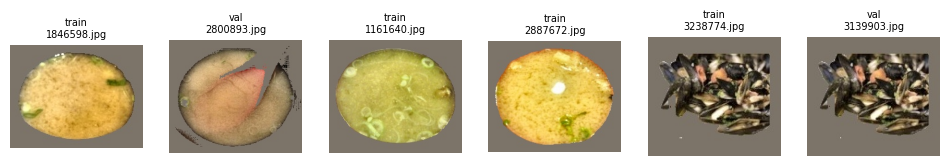

In [7]:
# near-duplicate check across splits (8x8 average hash). Report only: the split is fixed by the team.
def ahash(path):
    g = np.asarray(Image.open(path).convert("L").resize((8, 8), Image.BILINEAR), dtype=np.float32)
    return np.packbits(g > g.mean()).tobytes()

df_all["ahash"] = [ahash(p) for p in df_all.path]
dup = df_all[df_all.duplicated("ahash", keep=False)].sort_values("ahash")
cross = dup.groupby("ahash").filter(lambda g: g.split.nunique() > 1)
print(f"{dup.ahash.nunique()} hash groups with >1 image; {cross.ahash.nunique()} of them span different splits")
if len(cross):
    show = cross.groupby("ahash").head(2).head(12)
    fig, axes = plt.subplots(1, len(show), figsize=(2 * len(show), 2.4), squeeze=False)
    for ax, (_, r) in zip(axes[0], show.iterrows()):
        ax.imshow(Image.open(r.path)); ax.set_title(f"{r.split}\n{r.relpath.split('/')[-1]}", fontsize=7); ax.axis("off")
    plt.show()

In [8]:
# 6 random training images per class
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(K, 6, figsize=(12, 2 * K))
for i, c in enumerate(CLASSES):
    rows = df_all[(df_all.split == "train") & (df_all.label == c)]
    for j, p in enumerate(rng.choice(rows.path.values, 6, replace=False)):
        ax = axes[i, j]; ax.imshow(Image.open(p)); ax.set_xticks([]); ax.set_yticks([])
        if j == 0: ax.set_ylabel(c, rotation=0, ha="right", fontsize=9)
finish(fig, f"{DATASET}: train samples", "samples")

sizes = np.array([Image.open(p).size for p in df_all.path])
aspect = sizes.max(1) / sizes.min(1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(sizes[:, 0], bins=40, alpha=0.6, label="width"); axes[0].hist(sizes[:, 1], bins=40, alpha=0.6, label="height")
axes[0].set_title("image size (px)"); axes[0].legend()
axes[1].hist(aspect, bins=40); axes[1].set_title(f"aspect ratio (long/short); {np.mean(aspect > 4 / 3):.0%} wider than 4:3")
plt.tight_layout(); plt.show()

Output hidden; open in https://colab.research.google.com to view.

,n,fallback_rate,mask_area_median
split,,,
train,5780,0.0092,0.4073
val,1930,0.0140,0.4155
test,1920,0.0063,0.4235


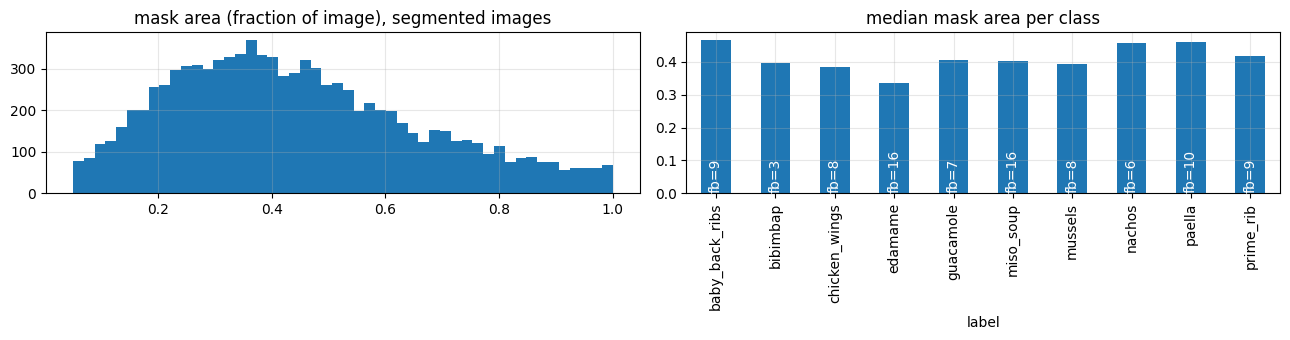

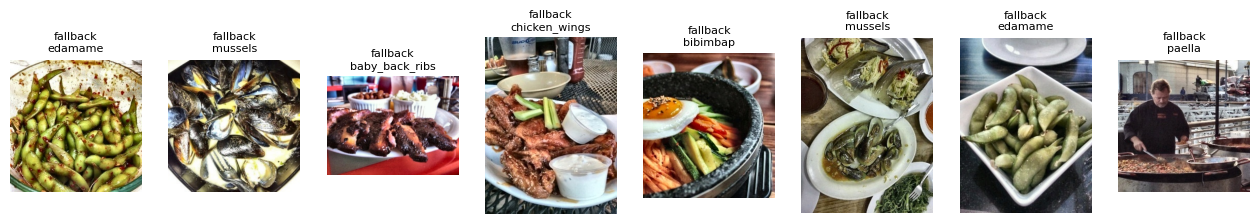

In [9]:
GSAM_STATS = META / "gsam_stats.csv"
HAS_GSAM = DATASET.startswith("03") and GSAM_STATS.exists()
if HAS_GSAM:
    gs = pd.read_csv(GSAM_STATS)
    gs["label"] = gs.relpath.str.split("/").str[1]
    display(gs.groupby("split").agg(n=("fallback", "size"), fallback_rate=("fallback", "mean"),
                                    mask_area_median=("mask_area", "median")).loc[["train", "val", "test"]])
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
    axes[0].hist(gs[gs.fallback == 0].mask_area, bins=50); axes[0].set_title("mask area (fraction of image), segmented images")
    per_cls = gs.groupby("label").agg(mask_area=("mask_area", "median"), fallbacks=("fallback", "sum"))
    per_cls.mask_area.plot.bar(ax=axes[1]); axes[1].set_title("median mask area per class")
    for i, n in enumerate(per_cls.fallbacks): axes[1].text(i, 0.01, f"fb={n}", ha="center", rotation=90, color="white")
    plt.tight_layout(); savefig(fig, "gsam_stats"); plt.show()

    fb = gs[gs.fallback == 1].sample(min(8, int(gs.fallback.sum())), random_state=SEED)
    fig, axes = plt.subplots(1, len(fb), figsize=(2 * len(fb), 2.4), squeeze=False)
    for ax, (_, r) in zip(axes[0], fb.iterrows()):
        ax.imshow(Image.open(DATA_ROOT / DATASET / r.relpath)); ax.set_title(f"fallback\n{r.label}", fontsize=8); ax.axis("off")
    plt.show()
else:
    print("no GSAM stats for this dataset; section 10 will be skipped")

## 2. Input pipeline
Pad to square (grey) → 224×224. Train adds a mild random crop (70–100% of the area) and a horizontal flip.
The same transform is used for CNN and ResNet-50; CLIP and the classical features use the same pad + resize with their own normalisation / size.

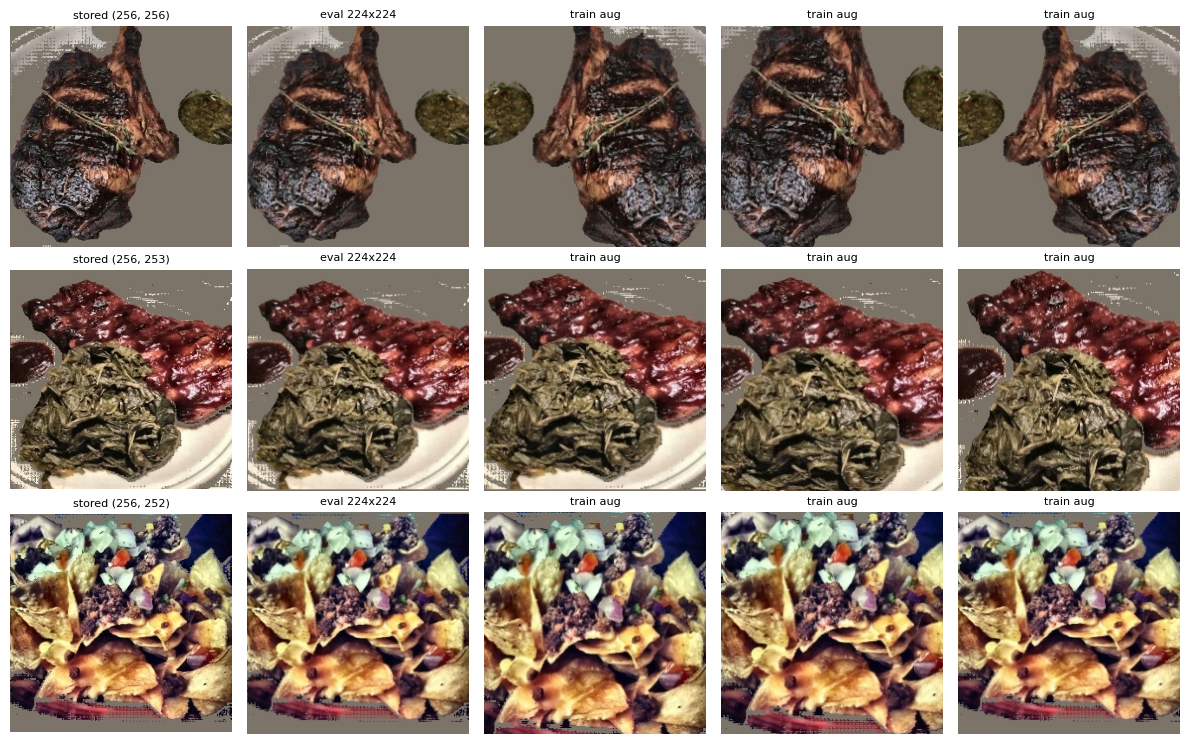

In [10]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
CLIP_MEAN, CLIP_STD = [0.48145466, 0.4578275, 0.40821073], [0.26862954, 0.26130258, 0.27577711]


def pad_to_square(img, fill=PAD_FILL):
    w, h = img.size
    s = max(w, h)
    out = Image.new("RGB", (s, s), fill)
    out.paste(img, ((s - w) // 2, (s - h) // 2))
    return out


train_tf = T.Compose([T.Lambda(pad_to_square),
                      T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
                      T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
eval_tf = T.Compose([T.Lambda(pad_to_square), T.Resize((IMG_SIZE, IMG_SIZE)),
                     T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
clip_tf = T.Compose([T.Lambda(pad_to_square), T.Resize((IMG_SIZE, IMG_SIZE)),
                     T.ToTensor(), T.Normalize(CLIP_MEAN, CLIP_STD)])


def show_tensor(t, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """Normalised CHW tensor -> HWC image in [0, 1] for plotting."""
    x = t.cpu() * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]
    return x.clamp(0, 1).permute(1, 2, 0).numpy()


class FoodDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths, self.labels, self.transform = frame.path.tolist(), frame.y.tolist(), transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return self.transform(Image.open(self.paths[i]).convert("RGB")), self.labels[i]


def make_loader(split, transform, shuffle=False, batch_size=None):
    return DataLoader(FoodDataset(splits[split], transform), batch_size=batch_size or (BATCH_SIZE if shuffle else EVAL_BATCH_SIZE),
                      shuffle=shuffle, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                      persistent_workers=NUM_WORKERS > 0)


# what the models see
demo = splits["train"].sample(3, random_state=SEED)
fig, axes = plt.subplots(3, 5, figsize=(12, 7.5))
for row, (_, r) in zip(axes, demo.iterrows()):
    img = Image.open(r.path).convert("RGB")
    row[0].imshow(img); row[0].set_title(f"stored {img.size}", fontsize=8)
    row[1].imshow(show_tensor(eval_tf(img))); row[1].set_title("eval 224x224", fontsize=8)
    for ax in row[2:]:
        ax.imshow(show_tensor(train_tf(img))); ax.set_title("train aug", fontsize=8)
    for ax in row: ax.axis("off")
plt.tight_layout(); savefig(fig, "transforms"); plt.show()

## 3. Evaluation toolkit (shared by all models)
- **top-k accuracy**: true class among the k highest scores. With 10 classes top-5 is close to 100% for any decent model, so top-1 and macro-F1 are the headline numbers.
- **macro precision / recall / F1**: per-class values averaged with equal weight (the classes are balanced, so macro ≈ weighted).
- **AP** per class: area under the one-vs-rest precision–recall curve from the scores; **mAP** = mean over the 10 classes. It uses the ranking, not only the top-1 decision.
- **Confusion matrix**: yes, 10×10, as counts and row-normalised (the diagonal is per-class recall), plus a list of the most confused pairs.
- Saved per model in `results/<dataset>/<model>/`: `metrics.json`, `per_class_test.csv`, `predictions_{val,test}.csv` (one row per image with all 10 scores, needed for the cross-dataset test in section 11),
  and the **final model**: `model.pt` (CNN, ResNet-50, CLIP) or `model.joblib` (Logistic Regression, SVM, scaler included), plus `config.json`, which records what it is and how to rebuild it. Section 12 reloads any of them.

In [11]:
RESULTS = {}   # model name -> {"val": {...}, "test": {...}, "config": {...}}


def topk_accuracy(y, scores, k):
    top = np.argsort(-scores, axis=1)[:, :k]
    return float((top == y[:, None]).any(axis=1).mean())


def compute_metrics(y, scores):
    y = np.asarray(y)
    pred = scores.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    Y = label_binarize(y, classes=np.arange(K))
    ap = np.array([average_precision_score(Y[:, c], scores[:, c]) for c in range(K)])
    pc_p, pc_r, pc_f, support = precision_recall_fscore_support(y, pred, labels=np.arange(K), zero_division=0)
    per_class = pd.DataFrame({"precision": pc_p, "recall": pc_r, "f1": pc_f, "AP": ap, "support": support}, index=CLASSES)
    summary = {"top1": topk_accuracy(y, scores, 1), "top3": topk_accuracy(y, scores, 3), "top5": topk_accuracy(y, scores, 5),
               "macro_precision": float(p), "macro_recall": float(r), "macro_f1": float(f1), "mAP": float(np.nanmean(ap)), "n": int(len(y))}
    return summary, per_class


def macro_f1(y, scores):
    return f1_score(y, scores.argmax(1), average="macro", zero_division=0)


def plot_confusion(y, pred, title, name):
    cm = confusion_matrix(y, pred, labels=np.arange(K))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
    for ax, m, fmt, sub in [(axes[0], cm, "d", "counts"), (axes[1], cmn, ".2f", "row-normalised (diagonal = recall)")]:
        im = ax.imshow(m, cmap="Blues")
        ax.set_xticks(range(K), CLASSES, rotation=45, ha="right"); ax.set_yticks(range(K), CLASSES); ax.grid(False)
        for i in range(K):
            for j in range(K):
                ax.text(j, i, format(m[i, j], fmt), ha="center", va="center", fontsize=8,
                        color="white" if m[i, j] > m.max() / 2 else "black")
        ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{title}: {sub}")
        fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); savefig(fig, f"{name}_confusion"); plt.show()
    off = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(K) for j in range(K) if i != j and cm[i, j] > 0]
    return pd.DataFrame(sorted(off, key=lambda t: -t[2])[:8], columns=["true", "predicted", "count"])


def show_predictions(frame, y, scores, correct, title, name, n=12, is_prob=True):
    pred = scores.argmax(1)
    idx = np.flatnonzero((pred == y) if correct else (pred != y))
    if len(idx) == 0:
        print("no", "correct" if correct else "wrong", "predictions"); return
    idx = np.random.default_rng(SEED).choice(idx, min(n, len(idx)), replace=False)
    cols = 6
    rows = int(np.ceil(len(idx) / cols))
    row_h = 3.3 if correct else 3.7          # room for the 2- or 3-line titles above each image
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, row_h * rows), squeeze=False)
    tag = "p" if is_prob else "s"
    for ax, i in zip(axes.ravel(), idx):
        top = np.argsort(-scores[i])[:2]
        ax.imshow(Image.open(frame.path[i]))
        txt = f"T: {CLASSES[y[i]]}\nP: {CLASSES[top[0]]} ({tag}={scores[i, top[0]]:.2f})"
        if not correct:
            txt += f"\n2nd: {CLASSES[top[1]]} ({scores[i, top[1]]:.2f})"
        ax.set_title(txt, fontsize=8, color="green" if correct else "red")
    for ax in axes.ravel(): ax.axis("off")
    finish(fig, title, name)


def save_predictions(name, split, y, scores):
    out = splits[split][["relpath", "label"]].copy()
    out["y_true"], out["y_pred"] = y, scores.argmax(1)
    out["pred_label"] = [CLASSES[i] for i in out.y_pred]
    for c in range(K):
        out[f"score_{CLASSES[c]}"] = scores[:, c]
    out.to_csv(OUT / name / f"predictions_{split}.csv", index=False)


def report_model(name, y_val, s_val, y_test, s_test, config, is_prob=True):
    """Final evaluation of a chosen model: val + test metrics, confusion matrix, examples, saved files."""
    (OUT / name).mkdir(exist_ok=True)
    sv, _ = compute_metrics(y_val, s_val)
    st, per_class = compute_metrics(y_test, s_test)
    RESULTS[name] = {"val": sv, "test": st, "config": config}
    display(pd.DataFrame([sv, st], index=["val", "test"]))
    display(per_class)
    display(plot_confusion(y_test, s_test.argmax(1), f"{name} (test)", name))
    show_predictions(splits["test"], y_test, s_test, True, f"{name}: correct test predictions", f"{name}_correct", is_prob=is_prob)
    show_predictions(splits["test"], y_test, s_test, False, f"{name}: wrong test predictions", f"{name}_wrong", is_prob=is_prob)
    save_predictions(name, "val", y_val, s_val)
    save_predictions(name, "test", y_test, s_test)
    per_class.to_csv(OUT / name / "per_class_test.csv")
    with open(OUT / name / "metrics.json", "w") as f:
        json.dump({"dataset": DATASET, "model": name, "seed": SEED, "run_mode": RUN_MODE, **RESULTS[name]}, f, indent=2, default=str)


def save_final(name, kind, model, arch=None):
    """Save the chosen model as results/<dataset>/<name>/model.{pt,joblib} + config.json (call after report_model).
    kind: "cnn" | "resnet50" | "clip" (torch, state_dict + architecture) or "sklearn" (whole fitted pipeline)."""
    import joblib
    d = OUT / name
    d.mkdir(exist_ok=True)
    arch = json.loads(json.dumps(arch or {}, default=str))   # plain Python types, so torch.load(weights_only=True) can read it
    if kind == "sklearn":
        file = "model.joblib"
        joblib.dump(model, d / file)
    elif kind == "clip":
        file = "model.pt"
        torch.save({"kind": kind, "arch": arch, "classes": CLASSES, "text_emb": model.text_emb.cpu()}, d / file)
    else:
        file = "model.pt"
        torch.save({"kind": kind, "arch": arch, "classes": CLASSES,
                    "state_dict": {k: v.cpu() for k, v in model.state_dict().items()}}, d / file)
    config = {"dataset": DATASET, "model": name, "kind": kind, "file": file, "arch": arch, "classes": CLASSES,
              "preprocessing": {"pad_to_square_fill": PAD_FILL, "img_size": IMG_SIZE,
                                "normalize": "clip" if kind == "clip" else "imagenet",
                                "classical_features": CLASSICAL_FEATURES if kind == "sklearn" else None},
              "seed": SEED, "run_mode": RUN_MODE, "torch": torch.__version__,
              "val_macro_f1": RESULTS.get(name, {}).get("val", {}).get("macro_f1"),
              "test_macro_f1": RESULTS.get(name, {}).get("test", {}).get("macro_f1"),
              "saved_at": time.strftime("%Y-%m-%d %H:%M:%S")}
    with open(d / "config.json", "w") as f:
        json.dump(config, f, indent=2, default=str)
    size = (d / file).stat().st_size / 1e6
    print(f"saved {d / file} ({size:.1f} MB) + config.json")

In [12]:
# shared PyTorch training loop (CNN and ResNet-50)
SCALER = torch.amp.GradScaler("cuda", enabled=USE_AMP)


def set_train_mode(model):
    """train() but keep frozen BatchNorm layers in eval mode, so a frozen backbone's running stats don't change."""
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    set_train_mode(model) if training else model.eval()
    total, ys, ps = 0.0, [], []
    for x, y_cpu in loader:
        # non_blocking copies only on CUDA: on MPS with torch <= 2.12 they can deliver corrupted labels
        x, y = x.to(DEVICE, non_blocking=NON_BLOCKING), y_cpu.to(DEVICE, non_blocking=NON_BLOCKING)
        with torch.set_grad_enabled(training), torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
            loss = F.cross_entropy(logits, y, label_smoothing=LABEL_SMOOTHING if training else 0.0)
        if training:
            optimizer.zero_grad(set_to_none=True)
            SCALER.scale(loss).backward()
            SCALER.step(optimizer)
            SCALER.update()
        total += loss.item() * len(y)
        ys.append(y_cpu); ps.append(logits.detach().float().softmax(1).cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return total / len(y), y, p


def fit(name, build, cfg, max_epochs, patience, lr, weight_decay):
    """Train with AdamW + cosine LR, keep the epoch with the best val macro-F1, stop after `patience` epochs without gain.
    Checkpoint files carry a hash of the config, so changing a grid value never reloads a stale model."""
    tag = hashlib.md5(str((cfg, max_epochs, patience, lr, weight_decay, LABEL_SMOOTHING, IMG_SIZE)).encode()).hexdigest()[:8]
    ckpt, hist_path = CKPT_DIR / f"{name}_{tag}.pt", CKPT_DIR / f"{name}_{tag}_history.csv"
    seed_everything()
    model = build().to(DEVICE)
    if ckpt.exists() and hist_path.exists() and not RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        print(f"{name}: loaded saved model {ckpt.name}")
        return model, pd.read_csv(hist_path), ckpt
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{name}: {n_train / 1e6:.2f}M trainable params")
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)
    train_dl, val_dl = make_loader("train", train_tf, shuffle=True), make_loader("val", eval_tf)
    rows, best, best_epoch, wait = [], -1.0, 0, 0
    for epoch in range(1, max_epochs + 1):
        t0, lr_now = time.time(), opt.param_groups[0]["lr"]
        tr_loss, tr_y, tr_p = run_epoch(model, train_dl, opt)
        va_loss, va_y, va_p = run_epoch(model, val_dl)
        sched.step()
        row = dict(epoch=epoch, lr=lr_now, train_loss=tr_loss, val_loss=va_loss,
                   train_acc=(tr_p.argmax(1) == tr_y).mean(), val_acc=(va_p.argmax(1) == va_y).mean(),
                   train_f1=macro_f1(tr_y, tr_p), val_f1=macro_f1(va_y, va_p), sec=time.time() - t0)
        rows.append(row)
        print(f"  ep {epoch:2d} | loss {tr_loss:.3f}/{va_loss:.3f} | F1 {row['train_f1']:.3f}/{row['val_f1']:.3f} | {row['sec']:.0f}s")
        if row["val_f1"] > best:
            best, best_epoch, wait = row["val_f1"], epoch, 0
            torch.save(model.state_dict(), ckpt)
        else:
            wait += 1
            if wait >= patience:
                print(f"  early stop: no val gain for {patience} epochs")
                break
    hist = pd.DataFrame(rows)
    hist["best"] = hist.epoch == best_epoch
    hist.to_csv(hist_path, index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model, hist, ckpt


def load_trained(ckpt, build):
    model = build().to(DEVICE)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model.eval()


@torch.no_grad()
def predict(model, split, transform=None):
    _, y, p = run_epoch(model, make_loader(split, transform or eval_tf))
    return y, p


def plot_learning_curves(hists, title, name):
    """One row per config: loss and macro-F1 per epoch, train vs val, dashed line at the kept epoch."""
    fig, axes = plt.subplots(len(hists), 2, figsize=(12, 3 * len(hists)), squeeze=False)
    for row, (cfg_name, h) in zip(axes, hists.items()):
        best = h.loc[h.best, "epoch"].iloc[0]
        for ax, metric in zip(row, ("loss", "f1")):
            ax.plot(h.epoch, h[f"train_{metric}"], "o-", ms=3, label="train")
            ax.plot(h.epoch, h[f"val_{metric}"], "o-", ms=3, label="val")
            ax.axvline(best, ls="--", c="gray", lw=1)
            ax.set_title(f"{cfg_name}: {'loss' if metric == 'loss' else 'macro-F1'} (kept epoch {best})", fontsize=10)
            ax.set_xlabel("epoch"); ax.legend()
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    finish(fig, title, name)


def plot_grid_summary(table, x, title, name, logx=False):
    """Train vs val macro-F1 at the kept epoch for each config: the 'elbow' plot."""
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.plot(table[x].astype(str) if not logx else table[x], table.train_f1, "o-", label="train")
    ax.plot(table[x].astype(str) if not logx else table[x], table.val_f1, "o-", label="val")
    if logx: ax.set_xscale("log")
    best = table.val_f1.idxmax()
    ax.scatter([table[x].astype(str)[best] if not logx else table[x][best]], [table.val_f1[best]], s=160,
               facecolors="none", edgecolors="red", lw=2, label="chosen (best val)", zorder=5)
    ax.set_xlabel(x); ax.set_ylabel("macro-F1"); ax.set_title(title); ax.legend()
    plt.tight_layout(); savefig(fig, name); plt.show()

## 4. Model 1 — CLIP ViT-B/32 zero-shot (baseline)
No training: each class name goes into a text prompt, and the image is assigned to the class whose text embedding is closest.
A plain ImageNet ResNet can't do this (its output is the 1,000 ImageNet classes), which is why CLIP is the zero-shot baseline.
The only choice is the prompt template, picked on val. There is no train curve because nothing is fitted.

In [13]:
from transformers import CLIPModel, AutoTokenizer

clip = CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval()
for p in clip.parameters():
    p.requires_grad_(False)
clip_tok = AutoTokenizer.from_pretrained(CLIP_ID)


@torch.no_grad()
def clip_text_embeddings(templates):
    embs = []
    for c in CLASSES:
        t = clip_tok([tpl.format(c.replace("_", " ")) for tpl in templates], padding=True, return_tensors="pt").to(DEVICE)
        e = clip.text_projection(clip.text_model(input_ids=t["input_ids"], attention_mask=t["attention_mask"]).pooler_output)
        embs.append(F.normalize(F.normalize(e, dim=-1).mean(0), dim=0))
    return torch.stack(embs)


class CLIPZeroShot(nn.Module):
    """Image -> class logits (scaled cosine similarity to the class text embeddings)."""
    def __init__(self, clip, text_emb):
        super().__init__()
        self.clip = clip
        self.register_buffer("text_emb", text_emb)

    def forward(self, x):
        f = self.clip.visual_projection(self.clip.vision_model(pixel_values=x).pooler_output)
        return self.clip.logit_scale.exp() * F.normalize(f, dim=-1) @ self.text_emb.T


@torch.no_grad()
def clip_image_embeddings(split):
    cache = OUT / f"clip_img_{split}.pt"
    if cache.exists() and not RETRAIN:
        return torch.load(cache).to(DEVICE)
    feats = []
    for x, _ in make_loader(split, clip_tf):
        f = clip.visual_projection(clip.vision_model(pixel_values=x.to(DEVICE)).pooler_output)
        feats.append(F.normalize(f, dim=-1))
    feats = torch.cat(feats)
    torch.save(feats.cpu(), cache)
    return feats


img_emb = {s: clip_image_embeddings(s) for s in ("val", "test")}
scale = clip.logit_scale.exp()
rows = []
for tname, templates in TEMPLATE_SETS.items():
    s_val = (scale * img_emb["val"] @ clip_text_embeddings(templates).T).softmax(1).cpu().numpy()
    rows.append({"templates": tname, "val_top1": topk_accuracy(y_split["val"], s_val, 1), "val_f1": macro_f1(y_split["val"], s_val)})
clip_grid = pd.DataFrame(rows)
display(clip_grid)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.bar(clip_grid.templates, clip_grid.val_f1)
for i, v in enumerate(clip_grid.val_f1): ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
ax.set_ylabel("val macro-F1"); ax.set_title("CLIP zero-shot: prompt template (val)"); ax.set_ylim(0, 1)
plt.tight_layout(); savefig(fig, "clip_templates"); plt.show()

best_t = clip_grid.loc[clip_grid.val_f1.idxmax(), "templates"]
clip_model = CLIPZeroShot(clip, clip_text_embeddings(TEMPLATE_SETS[best_t])).eval()
s = {sp: (scale * img_emb[sp] @ clip_model.text_emb.T).softmax(1).cpu().numpy() for sp in ("val", "test")}
print("chosen templates:", best_t)
report_model("clip_zeroshot", y_split["val"], s["val"], y_split["test"], s["test"], {"templates": TEMPLATE_SETS[best_t]})
save_final("clip_zeroshot", "clip", clip_model, {"clip_id": CLIP_ID, "templates": TEMPLATE_SETS[best_t]})

Output hidden; open in https://colab.research.google.com to view.

## 5. Model 2 — Classical: handcrafted features → Logistic Regression and SVM
An SVM or logistic regression can't learn well from 150,528 raw pixels, so each image becomes a fixed feature vector first:

| block | what it measures | dims |
|---|---|---|
| HSV colour histogram 8×8×8 | which colours are present | 512 |
| HOG (128×128 image, 16 px cells) | edge / shape directions | 1,764 |
| LBP uniform (8,1) + (16,2) | fine texture | 28 |

Background removal changes all three directly, so this is where the segmentation effect is most visible.
(`CLASSICAL_FEATURES = "resnet50"` swaps in frozen ImageNet ResNet-50 embeddings instead, a "linear probe". That is a useful extra, but it is no longer classical.)

**Validation curve / elbow.** For each `C` we fit on train and score both train and val. Small `C` = strong regularisation (underfits: both low).
Large `C` = weak regularisation (overfits: train → 1.0, val falls). Train usually stays above val instead of crossing it, so the point we keep is where **val peaks**,
just before the gap opens. That is the elbow.

In [14]:
import cv2
from joblib import Parallel, delayed
from skimage.feature import hog, local_binary_pattern
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.exceptions import ConvergenceWarning


def handcrafted(path):
    rgb = np.asarray(pad_to_square(Image.open(path).convert("RGB")).resize((128, 128), Image.BILINEAR))
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    color = cv2.calcHist([hsv], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256]).ravel()
    color /= color.sum() + 1e-8
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    shape = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm="L2-Hys")
    texture = []
    for p, r in ((8, 1), (16, 2)):
        h, _ = np.histogram(local_binary_pattern(gray, p, r, method="uniform"), bins=p + 2, range=(0, p + 2))
        texture.append(h / h.sum())
    return np.concatenate([color, shape, *texture]).astype(np.float32)


@torch.no_grad()
def resnet_embeddings(split):
    m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
    m.fc = nn.Identity()
    m = m.to(DEVICE).eval()
    return np.concatenate([m(x.to(DEVICE)).cpu().numpy() for x, _ in make_loader(split, eval_tf)])


def load_features(split):
    cache = OUT / f"features_{CLASSICAL_FEATURES}_{split}.npz"
    if cache.exists() and not RETRAIN:
        z = np.load(cache, allow_pickle=True)
        if list(z["relpath"]) == splits[split].relpath.tolist():
            return z["X"]
    t0 = time.time()
    if CLASSICAL_FEATURES == "handcrafted":
        X = np.stack(Parallel(n_jobs=-1, batch_size=32)(delayed(handcrafted)(p) for p in splits[split].path))
    else:
        X = resnet_embeddings(split)
    np.savez(cache, X=X, relpath=splits[split].relpath.values)
    print(f"{split}: features {X.shape} in {time.time() - t0:.0f}s")
    return X


X = {s: load_features(s) for s in ("train", "val", "test")}
print({s: v.shape for s, v in X.items()})

train: features (5780, 2304) in 96s
val: features (1930, 2304) in 28s
test: features (1920, 2304) in 28s
{'train': (5780, 2304), 'val': (1930, 2304), 'test': (1920, 2304)}


Logistic Regression
  {'C': 0.0001} -> train 0.507 | val 0.442 | 7s
  {'C': 0.001} -> train 0.676 | val 0.479 | 15s
  {'C': 0.01} -> train 0.893 | val 0.466 | 22s
  {'C': 0.1} -> train 0.998 | val 0.440 | 25s
  {'C': 1} -> train 1.000 | val 0.427 | 25s
  {'C': 10} -> train 1.000 | val 0.421 | 15s
  {'C': 100} -> train 1.000 | val 0.416 | 11s


,C,train_f1,val_f1,sec
0,0.0001,0.5067,0.4420,6.7619
1,0.0010,0.6762,0.4790,14.9003
2,0.0100,0.8928,0.4661,22.4714
3,0.1000,0.9978,0.4398,24.6784
4,1.0000,1.0000,0.4266,24.7588
5,10.0000,1.0000,0.4211,14.7863
6,100.0000,1.0000,0.4161,10.8973


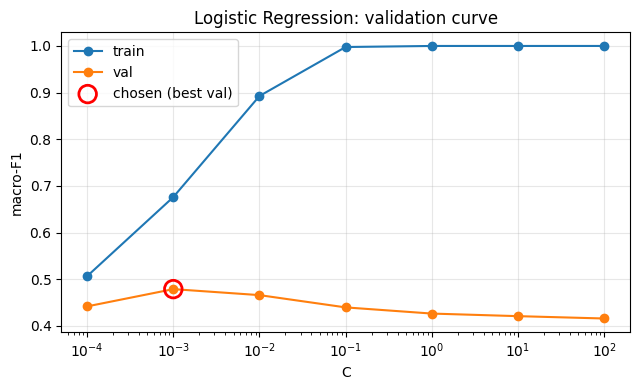

In [15]:
def sweep(make_model, grid, name):
    """Fit every config on train, score train and val. Cached to CSV so a re-run doesn't refit the whole grid."""
    path = OUT / f"{name}_grid_{CLASSICAL_FEATURES}_{hashlib.md5(str(grid).encode()).hexdigest()[:8]}.csv"
    if path.exists() and not RETRAIN:
        return pd.read_csv(path)
    rows = []
    for cfg in grid:
        t0 = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            m = make_model(**cfg).fit(X["train"], y_split["train"])
        rows.append({**cfg, "train_f1": f1_score(y_split["train"], m.predict(X["train"]), average="macro"),
                     "val_f1": f1_score(y_split["val"], m.predict(X["val"]), average="macro"), "sec": time.time() - t0})
        print(f"  {cfg} -> train {rows[-1]['train_f1']:.3f} | val {rows[-1]['val_f1']:.3f} | {rows[-1]['sec']:.0f}s")
    table = pd.DataFrame(rows)
    table.to_csv(path, index=False)
    return table


def make_logreg(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))


n_feat = X["train"].shape[1]
def make_svm(C, gamma_mult):
    return make_pipeline(StandardScaler(), SVC(C=C, gamma=gamma_mult / n_feat, kernel="rbf", decision_function_shape="ovr"))


print("Logistic Regression")
lr_grid = sweep(make_logreg, [dict(C=c) for c in LOGREG_C], "logreg")
display(lr_grid)
plot_grid_summary(lr_grid, "C", "Logistic Regression: validation curve", "logreg_curve", logx=True)

SVM (RBF)
  {'C': 0.1, 'gamma_mult': 0.3} -> train 0.334 | val 0.300 | 173s
  {'C': 1, 'gamma_mult': 0.3} -> train 0.624 | val 0.463 | 154s
  {'C': 10, 'gamma_mult': 0.3} -> train 0.971 | val 0.494 | 156s
  {'C': 100, 'gamma_mult': 0.3} -> train 1.000 | val 0.477 | 155s
  {'C': 1000, 'gamma_mult': 0.3} -> train 1.000 | val 0.477 | 164s
  {'C': 0.1, 'gamma_mult': 1} -> train 0.405 | val 0.341 | 169s
  {'C': 1, 'gamma_mult': 1} -> train 0.871 | val 0.482 | 158s
  {'C': 10, 'gamma_mult': 1} -> train 1.000 | val 0.506 | 166s
  {'C': 100, 'gamma_mult': 1} -> train 1.000 | val 0.505 | 162s
  {'C': 1000, 'gamma_mult': 1} -> train 1.000 | val 0.505 | 160s
  {'C': 0.1, 'gamma_mult': 3} -> train 0.331 | val 0.214 | 167s
  {'C': 1, 'gamma_mult': 3} -> train 0.992 | val 0.427 | 174s
  {'C': 10, 'gamma_mult': 3} -> train 1.000 | val 0.452 | 166s
  {'C': 100, 'gamma_mult': 3} -> train 1.000 | val 0.452 | 172s
  {'C': 1000, 'gamma_mult': 3} -> train 1.000 | val 0.452 | 177s


C,0.100000,1.000000,10.000000,100.000000,1000.000000
gamma_mult,,,,,
0.300000,0.300,0.463,0.494,0.477,0.477
1.000000,0.341,0.482,0.506,0.505,0.505
3.000000,0.214,0.427,0.452,0.452,0.452


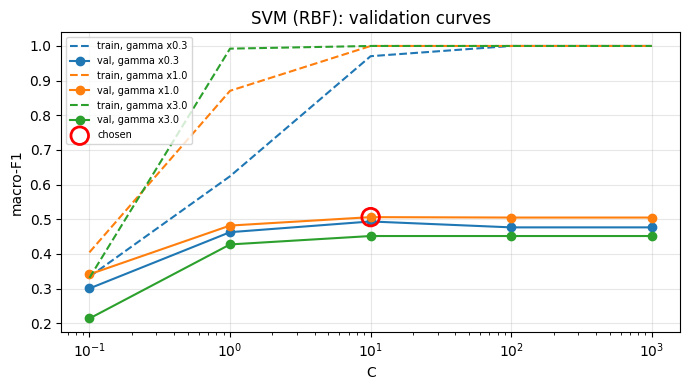

In [16]:
print("SVM (RBF)")
svm_grid = sweep(make_svm, [dict(C=c, gamma_mult=g) for g in SVM_GAMMA_MULT for c in SVM_C], "svm")
display(svm_grid.pivot(index="gamma_mult", columns="C", values="val_f1").style.background_gradient(cmap="Blues").format("{:.3f}"))

fig, ax = plt.subplots(figsize=(7, 4))
for i, (g, t) in enumerate(svm_grid.groupby("gamma_mult")):
    ax.plot(t.C, t.train_f1, "--", c=f"C{i}", label=f"train, gamma x{g}")
    ax.plot(t.C, t.val_f1, "o-", c=f"C{i}", label=f"val, gamma x{g}")
b = svm_grid.val_f1.idxmax()
ax.scatter([svm_grid.C[b]], [svm_grid.val_f1[b]], s=160, facecolors="none", edgecolors="red", lw=2, zorder=5, label="chosen")
ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("macro-F1"); ax.set_title("SVM (RBF): validation curves"); ax.legend(fontsize=7)
plt.tight_layout(); savefig(fig, "svm_curve"); plt.show()

In [17]:
best_lr = lr_grid.loc[lr_grid.val_f1.idxmax()]
logreg = make_logreg(C=float(best_lr.C)).fit(X["train"], y_split["train"])
print("Logistic Regression, chosen C =", best_lr.C)
report_model("logreg", y_split["val"], logreg.predict_proba(X["val"]), y_split["test"], logreg.predict_proba(X["test"]),
             {"features": CLASSICAL_FEATURES, "C": float(best_lr.C)})
save_final("logreg", "sklearn", logreg, {"features": CLASSICAL_FEATURES, "C": float(best_lr.C)})

Output hidden; open in https://colab.research.google.com to view.

In [18]:
best_svm = svm_grid.loc[svm_grid.val_f1.idxmax()]
svm = make_svm(C=float(best_svm.C), gamma_mult=float(best_svm.gamma_mult)).fit(X["train"], y_split["train"])
print(f"SVM, chosen C = {best_svm.C}, gamma = {best_svm.gamma_mult} / n_features")
# SVC has no calibrated probabilities; the one-vs-rest decision values rank the classes, which is all top-k and AP need
report_model("svm", y_split["val"], svm.decision_function(X["val"]), y_split["test"], svm.decision_function(X["test"]),
             {"features": CLASSICAL_FEATURES, "C": float(best_svm.C), "gamma_mult": float(best_svm.gamma_mult)}, is_prob=False)
save_final("svm", "sklearn", svm, {"features": CLASSICAL_FEATURES, "C": float(best_svm.C), "gamma_mult": float(best_svm.gamma_mult)})

Output hidden; open in https://colab.research.google.com to view.

## 6. Model 3 — CNN from scratch
VGG-style blocks of `[conv3×3-BN-ReLU] ×2 → maxpool`, channels doubling per block (32, 64, 128, …), then global average pooling → dropout → linear.
The tuning question is **depth** (3, 4 or 5 blocks); epochs are set by early stopping on val macro-F1.

Two kinds of graph:
1. **Learning curves** per config (loss and macro-F1 per epoch). Overfitting shows as train still improving while val flattens or gets worse. The dashed line marks the kept epoch.
2. **Train vs val against depth** at each config's kept epoch: the elbow plot.

Train scores are measured during the training pass (with augmentation and dropout on), which is standard and slightly underestimates them.

cnn_d3: 0.29M trainable params
  ep  1 | loss 1.886/1.694 | F1 0.358/0.371 | 28s
  ep  2 | loss 1.764/1.623 | F1 0.432/0.391 | 28s
  ep  3 | loss 1.704/1.710 | F1 0.466/0.384 | 28s
  ep  4 | loss 1.648/1.538 | F1 0.503/0.456 | 28s
  ep  5 | loss 1.616/1.437 | F1 0.519/0.500 | 27s
  ep  6 | loss 1.595/1.589 | F1 0.531/0.429 | 27s
  ep  7 | loss 1.551/1.362 | F1 0.561/0.551 | 28s
  ep  8 | loss 1.544/1.401 | F1 0.564/0.556 | 28s
  ep  9 | loss 1.520/1.338 | F1 0.573/0.557 | 28s
  ep 10 | loss 1.500/1.340 | F1 0.583/0.541 | 26s
  ep 11 | loss 1.480/1.336 | F1 0.587/0.561 | 28s
  ep 12 | loss 1.469/1.323 | F1 0.597/0.559 | 28s
  ep 13 | loss 1.446/1.305 | F1 0.610/0.573 | 28s
  ep 14 | loss 1.438/1.266 | F1 0.612/0.586 | 27s
  ep 15 | loss 1.443/1.312 | F1 0.613/0.563 | 27s
  ep 16 | loss 1.415/1.239 | F1 0.616/0.604 | 28s
  ep 17 | loss 1.398/1.305 | F1 0.638/0.576 | 27s
  ep 18 | loss 1.388/1.284 | F1 0.639/0.563 | 28s
  ep 19 | loss 1.379/1.165 | F1 0.643/0.616 | 26s
  ep 20 | loss 1.36

,n_blocks,base,dropout,name,epoch,train_f1,val_f1,ckpt
0,3,32,0.3,cnn_d3,36,0.7063,0.6985,/content/drive/MyDrive/food_classify/results/0...
1,4,32,0.3,cnn_d4,10,0.6132,0.6195,/content/drive/MyDrive/food_classify/results/0...
2,5,32,0.3,cnn_d5,40,0.8041,0.7515,/content/drive/MyDrive/food_classify/results/0...


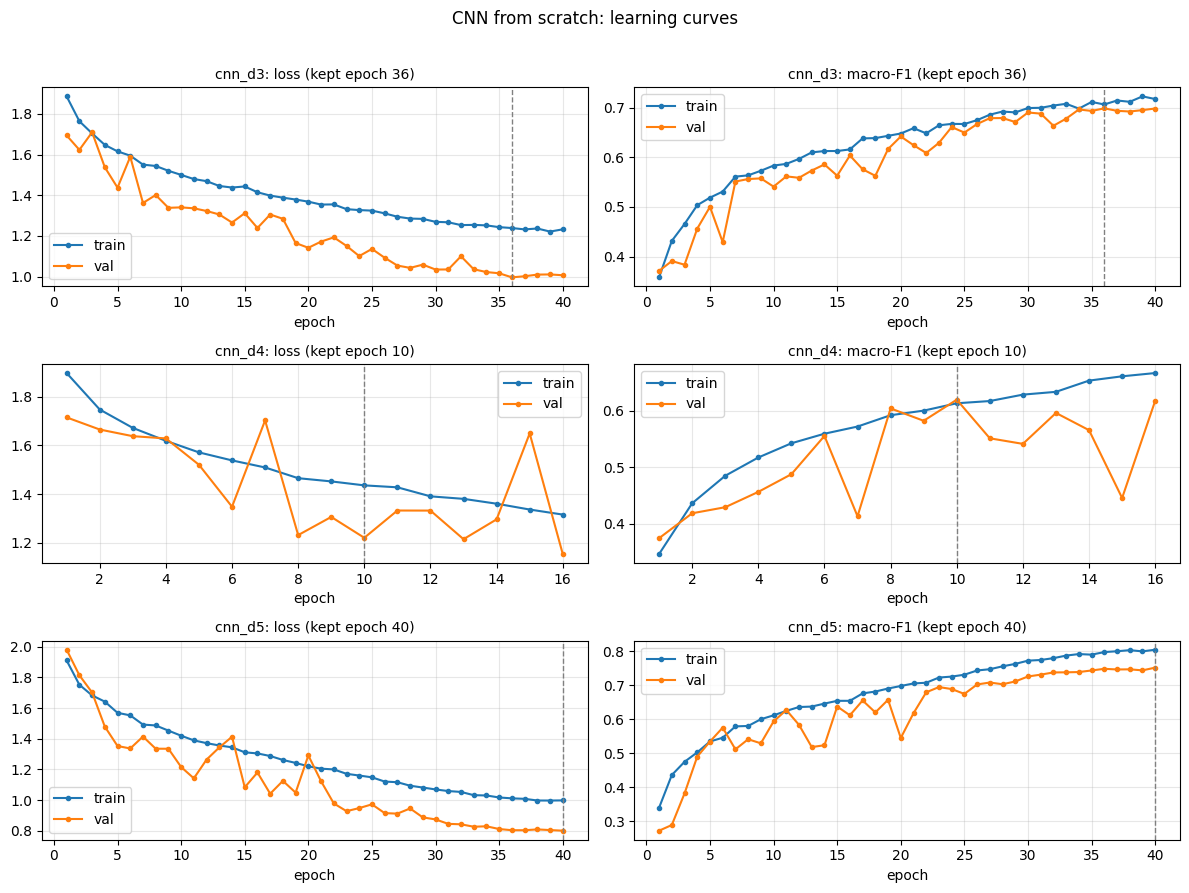

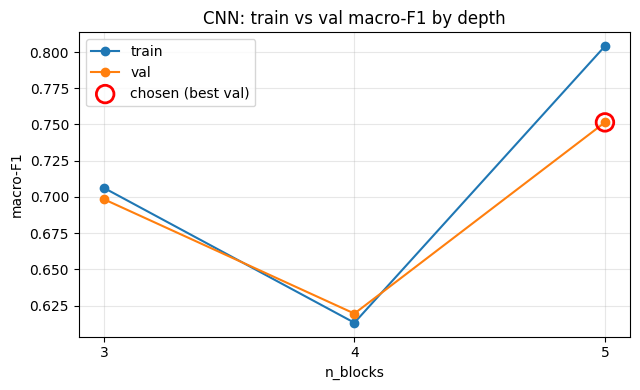

In [19]:
class SimpleCNN(nn.Module):
    def __init__(self, n_blocks=4, base=32, dropout=0.3, n_classes=K):
        super().__init__()
        layers, c_in = [], 3
        for i in range(n_blocks):
            c = base * 2 ** i
            layers += [nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                       nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                       nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


cnn_hists, cnn_rows = {}, []
for cfg in CNN_GRID:
    name = f"cnn_d{cfg['n_blocks']}"
    model, hist, ckpt = fit(name, lambda: SimpleCNN(**cfg), cfg, **CNN_TRAIN)
    cnn_hists[name] = hist
    kept = hist[hist.best].iloc[0]
    cnn_rows.append({**cfg, "name": name, "epoch": int(kept.epoch), "train_f1": kept.train_f1, "val_f1": kept.val_f1, "ckpt": str(ckpt)})
    del model
cnn_grid = pd.DataFrame(cnn_rows)
display(cnn_grid)
plot_learning_curves(cnn_hists, "CNN from scratch: learning curves", "cnn_learning_curves")
plot_grid_summary(cnn_grid, "n_blocks", "CNN: train vs val macro-F1 by depth", "cnn_depth")

In [20]:
best_cnn = cnn_grid.loc[cnn_grid.val_f1.idxmax()]
cnn_cfg = {"n_blocks": int(best_cnn.n_blocks), "base": int(best_cnn.base), "dropout": float(best_cnn.dropout)}
cnn_model = load_trained(best_cnn.ckpt, lambda: SimpleCNN(**cnn_cfg))
print("chosen:", best_cnn["name"], cnn_cfg)
yv, pv = predict(cnn_model, "val")
yt, pt = predict(cnn_model, "test")
report_model("cnn", yv, pv, yt, pt, {**cnn_cfg, **CNN_TRAIN, "epoch": int(best_cnn.epoch)})
save_final("cnn", "cnn", cnn_model, cnn_cfg)

Output hidden; open in https://colab.research.google.com to view.

## 7. Model 4 — ResNet-50 transfer learning (ImageNet weights)
New 10-class head (dropout 0.2 → linear). Tuning question: **how much of the pretrained network to fine-tune**.
- `fc`: only the head (feature extractor + classifier)
- `layer4`: last residual stage + head
- `all`: everything, with a smaller learning rate

Frozen BatchNorm layers stay in eval mode during training (`set_train_mode`); otherwise a "frozen" backbone would still drift.

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 161MB/s]


resnet50_fc: 0.02M trainable params
  ep  1 | loss 1.511/0.998 | F1 0.642/0.739 | 27s
  ep  2 | loss 1.132/0.847 | F1 0.767/0.765 | 31s
  ep  3 | loss 1.059/0.796 | F1 0.783/0.766 | 26s
  ep  4 | loss 1.013/0.759 | F1 0.806/0.779 | 26s
  ep  5 | loss 0.996/0.746 | F1 0.812/0.784 | 27s
  ep  6 | loss 0.977/0.735 | F1 0.818/0.794 | 27s
  ep  7 | loss 0.955/0.724 | F1 0.828/0.794 | 25s
  ep  8 | loss 0.949/0.716 | F1 0.834/0.793 | 26s
  ep  9 | loss 0.934/0.708 | F1 0.844/0.796 | 26s
  ep 10 | loss 0.931/0.712 | F1 0.842/0.797 | 25s
  ep 11 | loss 0.927/0.708 | F1 0.846/0.796 | 25s
  ep 12 | loss 0.920/0.704 | F1 0.851/0.794 | 26s
  ep 13 | loss 0.915/0.704 | F1 0.852/0.796 | 25s
  ep 14 | loss 0.917/0.704 | F1 0.849/0.795 | 25s
  early stop: no val gain for 4 epochs
resnet50_layer4: 14.99M trainable params
  ep  1 | loss 1.156/0.572 | F1 0.740/0.834 | 27s
  ep  2 | loss 0.822/0.586 | F1 0.872/0.820 | 27s
  ep  3 | loss 0.712/0.537 | F1 0.926/0.845 | 25s
  ep  4 | loss 0.641/0.550 | F1 0.

,unfreeze,lr,name,epoch,train_f1,val_f1,ckpt
0,fc,0.0010,resnet50_fc,10,0.8421,0.7967,/content/drive/MyDrive/food_classify/results/0...
1,layer4,0.0003,resnet50_layer4,9,0.9960,0.8595,/content/drive/MyDrive/food_classify/results/0...
2,all,0.0001,resnet50_all,14,0.9964,0.8662,/content/drive/MyDrive/food_classify/results/0...


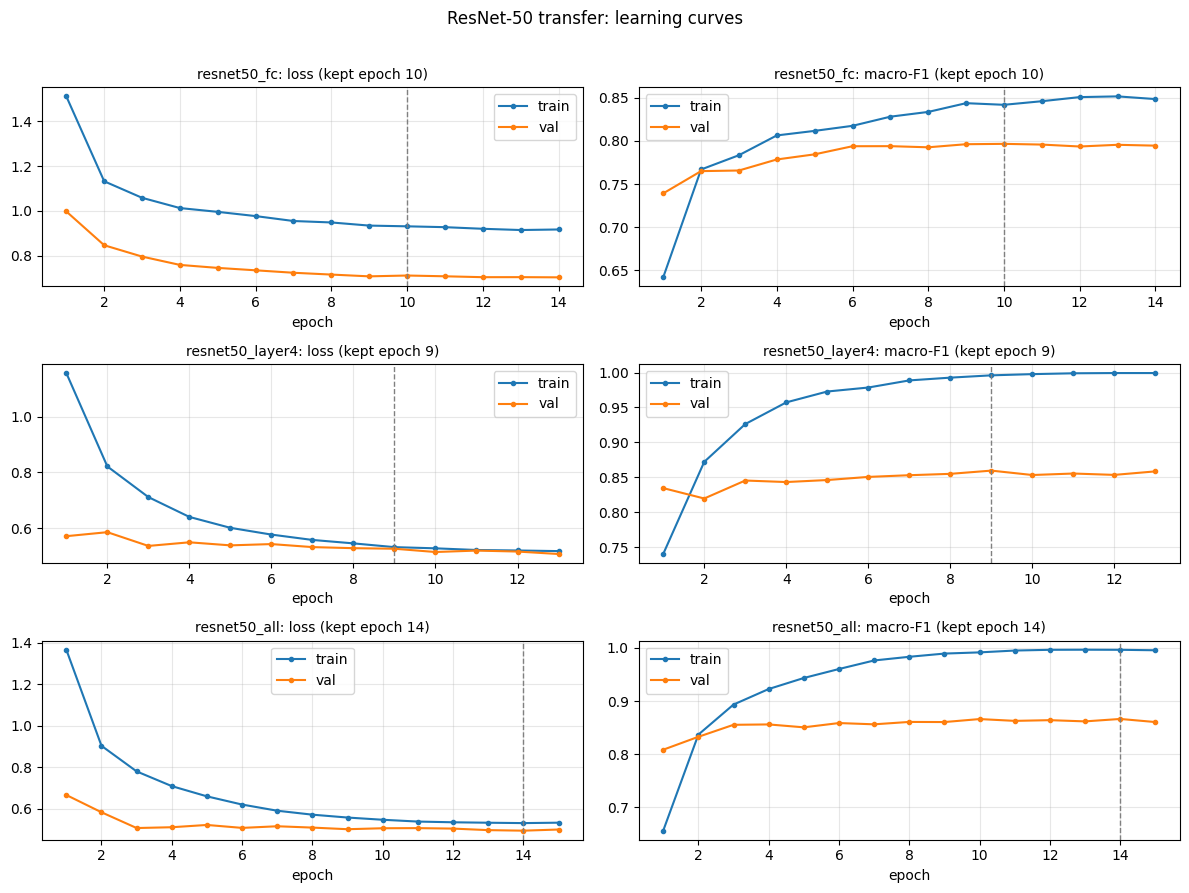

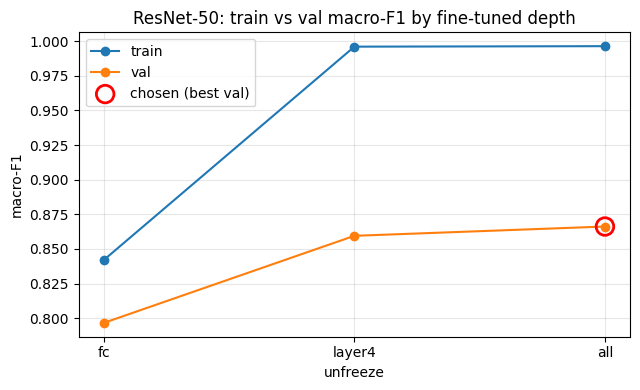

In [21]:
def make_resnet50(unfreeze, pretrained=True):
    m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
    m.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.fc.in_features, K))
    for p in m.parameters():
        p.requires_grad_(False)
    for part in {"fc": [m.fc], "layer4": [m.layer4, m.fc], "all": [m]}[unfreeze]:
        for p in part.parameters():
            p.requires_grad_(True)
    return m


rn_hists, rn_rows = {}, []
for cfg in RESNET_GRID:
    name = f"resnet50_{cfg['unfreeze']}"
    model, hist, ckpt = fit(name, lambda: make_resnet50(cfg["unfreeze"]), cfg, lr=cfg["lr"], **RESNET_TRAIN)
    rn_hists[name] = hist
    kept = hist[hist.best].iloc[0]
    rn_rows.append({**cfg, "name": name, "epoch": int(kept.epoch), "train_f1": kept.train_f1, "val_f1": kept.val_f1, "ckpt": str(ckpt)})
    del model
rn_grid = pd.DataFrame(rn_rows)
display(rn_grid)
plot_learning_curves(rn_hists, "ResNet-50 transfer: learning curves", "resnet_learning_curves")
plot_grid_summary(rn_grid, "unfreeze", "ResNet-50: train vs val macro-F1 by fine-tuned depth", "resnet_unfreeze")

chosen: resnet50_all


,top1,top3,top5,macro_precision,macro_recall,macro_f1,mAP,n
val,0.8658,0.9565,0.9808,0.8686,0.8658,0.8662,0.9267,1930
test,0.8781,0.9609,0.9828,0.8787,0.8781,0.8782,0.9403,1920


,precision,recall,f1,AP,support
baby_back_ribs,0.8441,0.8177,0.8307,0.9118,192
bibimbap,0.9058,0.9010,0.9034,0.9640,192
chicken_wings,0.8434,0.8698,0.8564,0.9207,192
edamame,0.9086,0.9323,0.9203,0.9658,192
guacamole,0.8860,0.8906,0.8883,0.9520,192
miso_soup,0.9787,0.9583,0.9684,0.9906,192
mussels,0.8711,0.8802,0.8756,0.9599,192
nachos,0.8049,0.8594,0.8312,0.8909,192
paella,0.8973,0.8646,0.8806,0.9282,192
prime_rib,0.8470,0.8073,0.8267,0.9196,192


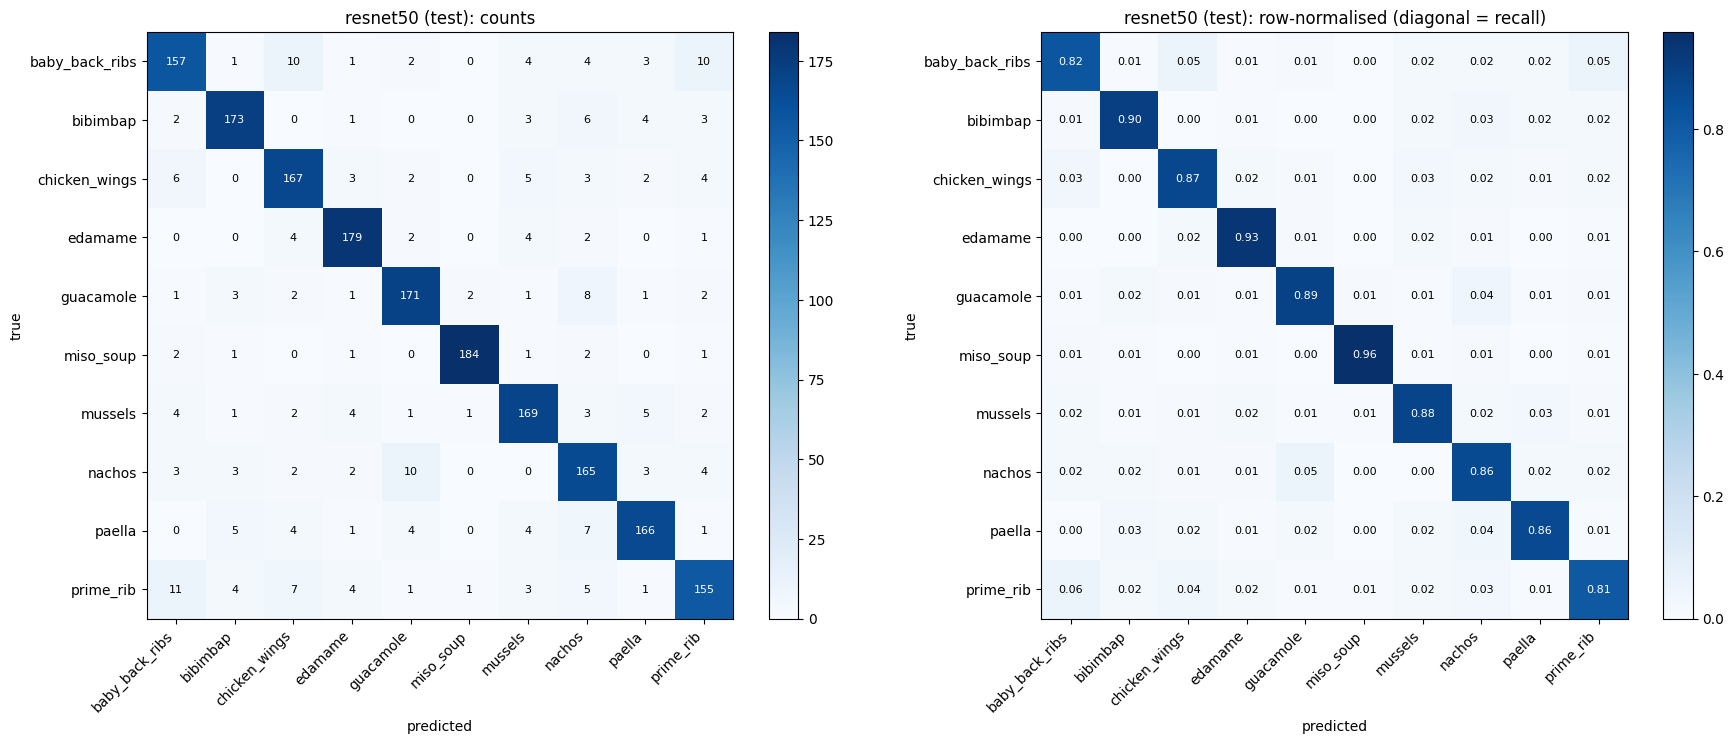

,true,predicted,count
0,prime_rib,baby_back_ribs,11
1,baby_back_ribs,chicken_wings,10
2,baby_back_ribs,prime_rib,10
3,nachos,guacamole,10
4,guacamole,nachos,8
5,paella,nachos,7
6,prime_rib,chicken_wings,7
7,bibimbap,nachos,6


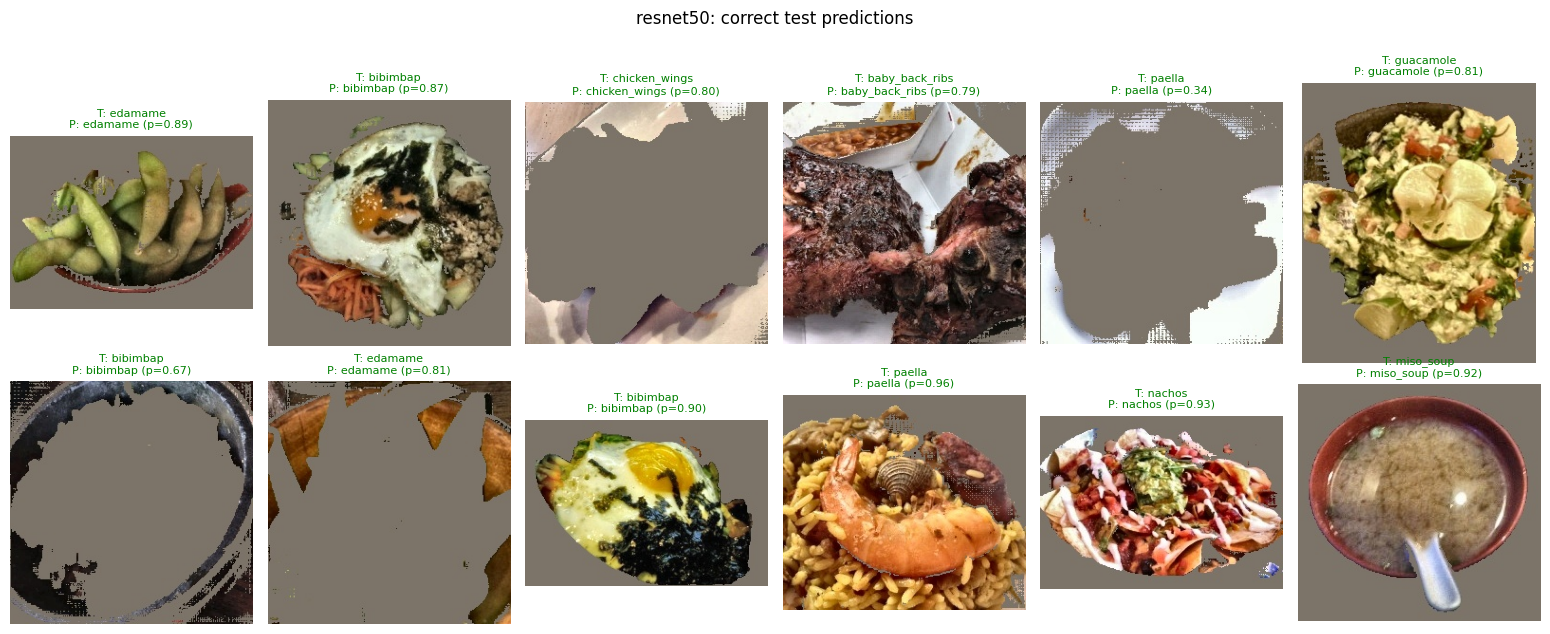

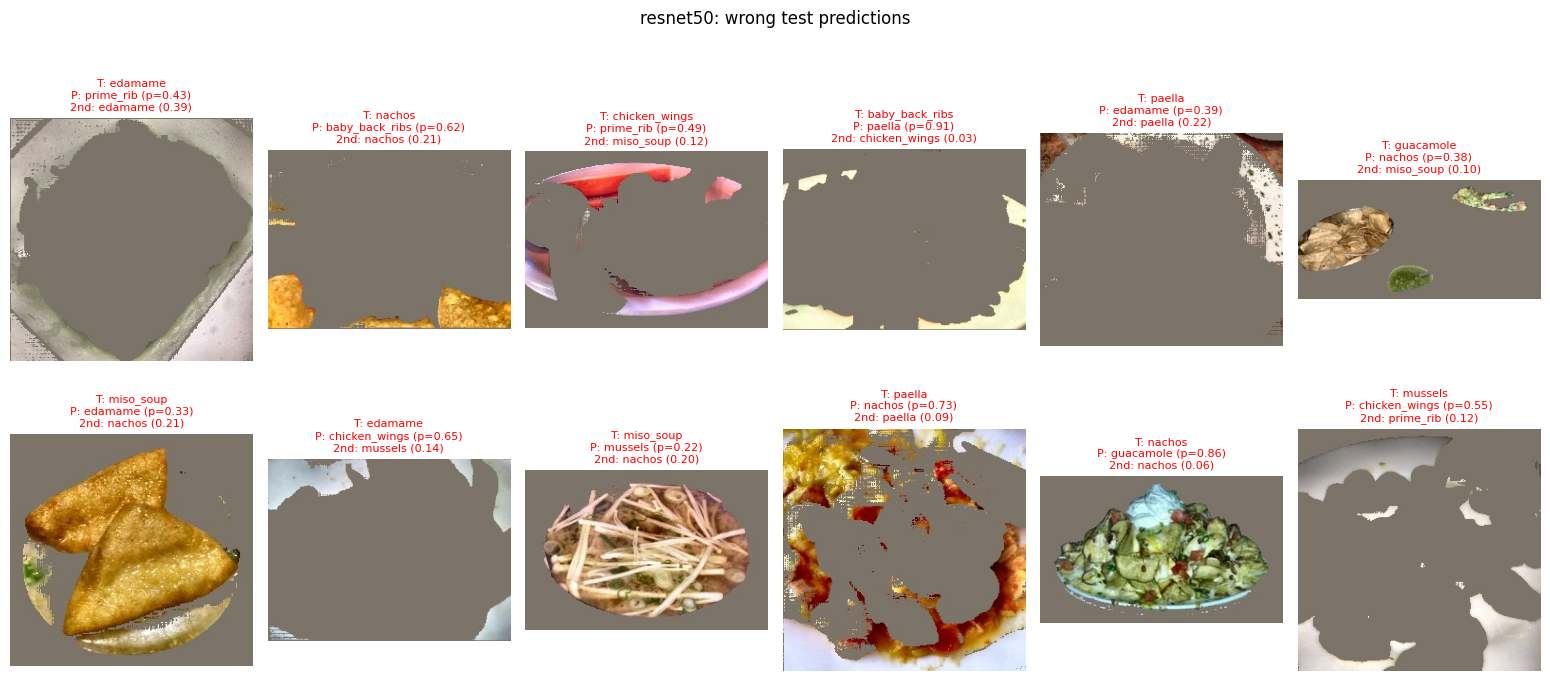

saved /content/drive/MyDrive/food_classify/results/03_denoise_clahe_gsam/resnet50/model.pt (94.4 MB) + config.json


In [22]:
best_rn = rn_grid.loc[rn_grid.val_f1.idxmax()]
rn_model = load_trained(best_rn.ckpt, lambda: make_resnet50(best_rn["unfreeze"]))
print("chosen:", best_rn["name"])
yv, pv = predict(rn_model, "val")
yt, pt = predict(rn_model, "test")
report_model("resnet50", yv, pv, yt, pt, {"unfreeze": best_rn["unfreeze"], "lr": float(best_rn.lr), **RESNET_TRAIN, "epoch": int(best_rn.epoch)})
save_final("resnet50", "resnet50", rn_model, {"unfreeze": best_rn["unfreeze"]})

## 8. Model comparison on this dataset

,val_macro_f1,top1,top3,top5,macro_precision,macro_recall,macro_f1,mAP
clip_zeroshot,0.694,0.696,0.855,0.915,0.733,0.696,0.699,0.811
logreg,0.479,0.476,0.762,0.882,0.476,0.476,0.475,0.473
svm,0.507,0.478,0.770,0.893,0.480,0.478,0.476,0.493
cnn,0.751,0.759,0.915,0.965,0.760,0.759,0.759,0.844
resnet50,0.866,0.878,0.961,0.983,0.879,0.878,0.878,0.940


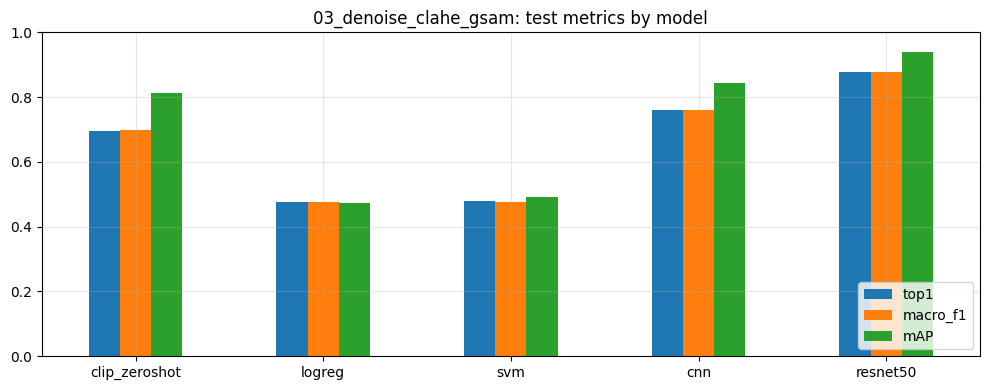

In [23]:
cols = ["top1", "top3", "top5", "macro_precision", "macro_recall", "macro_f1", "mAP"]
summary = pd.DataFrame({m: r["test"] for m, r in RESULTS.items()}).T[cols]
summary.insert(0, "val_macro_f1", [RESULTS[m]["val"]["macro_f1"] for m in summary.index])
display(summary.style.highlight_max(axis=0, color="#cde4ff").format("{:.3f}"))
summary.to_csv(OUT / "summary_test.csv")

fig, ax = plt.subplots(figsize=(10, 4))
summary[["top1", "macro_f1", "mAP"]].plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1); ax.set_title(f"{DATASET}: test metrics by model"); ax.legend(loc="lower right")
plt.tight_layout(); savefig(fig, "model_comparison"); plt.show()

## 9. Grad-CAM: what each model looks at
Grad-CAM weights the last convolutional feature map by the gradient of the predicted class score, so red = regions that pushed the model toward its prediction.
- CNN: last conv block. ResNet-50: `layer4`. CLIP ViT: the 7×7 patch tokens of the last transformer block (the same idea applied to tokens).
- The classical models have no gradients, so they have no Grad-CAM.

Two image sets:
1. **Fixed set**: 1 test image per class, picked by seed from the manifest. It is identical in 01 / 02 / 03, so you can put the three notebooks side by side.
2. Correct and wrong predictions of ResNet-50 (the strongest trained model).

In [24]:
class GradCAM:
    def __init__(self, model, layer, tokens=False):
        self.model, self.tokens = model, tokens
        self.handle = layer.register_forward_hook(self._hook)

    def _hook(self, module, inp, out):
        self.acts = out
        out.register_hook(lambda g: setattr(self, "grads", g))

    def __call__(self, x):
        self.model.eval()
        x = x.to(DEVICE).requires_grad_(True)   # makes the hook fire even when the backbone is frozen
        logits = self.model(x)
        cls = logits.argmax(1)
        self.model.zero_grad(set_to_none=True)
        logits.gather(1, cls[:, None]).sum().backward()
        A, G = self.acts.detach(), self.grads.detach()
        if self.tokens:                         # (B, 1+N, C) ViT tokens -> (B, C, h, w), CLS token dropped
            side = int((A.shape[1] - 1) ** 0.5)
            A, G = [t[:, 1:].transpose(1, 2).reshape(t.shape[0], -1, side, side) for t in (A, G)]
        cam = F.relu((G.mean((2, 3), keepdim=True) * A).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        cam = (cam - cam.amin((1, 2), keepdim=True)) / (cam.amax((1, 2), keepdim=True) - cam.amin((1, 2), keepdim=True) + 1e-8)
        return cam.cpu().numpy(), logits.detach().softmax(1).cpu().numpy()

    def remove(self):
        self.handle.remove()


cam_models = {   # name -> (model, target layer, transform, token input?)
    "CNN": (cnn_model, cnn_model.features[-2], eval_tf, False),
    "ResNet-50": (rn_model, rn_model.layer4, eval_tf, False),
    "CLIP": (clip_model, clip_model.clip.vision_model.encoder.layers[-1].layer_norm1, clip_tf, True),
}


def gradcam_grid(frame, title, name):
    cams = {m: GradCAM(model, layer, tok) for m, (model, layer, _, tok) in cam_models.items()}
    fig, axes = plt.subplots(len(frame), 1 + len(cams), figsize=(3 * (1 + len(cams)), 3.1 * len(frame)), squeeze=False)
    try:
        for row, (_, r) in zip(axes, frame.iterrows()):
            img = Image.open(r.path).convert("RGB")
            shown = np.asarray(pad_to_square(img).resize((IMG_SIZE, IMG_SIZE)))
            row[0].imshow(shown); row[0].set_title(f"true: {r.label}", fontsize=9)
            for ax, (m, cam) in zip(row[1:], cams.items()):
                heat, prob = cam(cam_models[m][2](img)[None])
                p = prob[0].argmax()
                ax.imshow(shown); ax.imshow(heat[0], cmap="jet", alpha=0.45)
                ax.set_title(f"{m}: {CLASSES[p]} ({prob[0, p]:.2f})", fontsize=9, color="green" if p == r.y else "red")
            for ax in row: ax.axis("off")
    finally:
        for c in cams.values(): c.remove()
    finish(fig, title, name)


fixed = splits["test"].groupby("label", group_keys=False).sample(1, random_state=SEED).reset_index(drop=True)
fixed[["relpath"]].to_csv(OUT / "gradcam_fixed_images.csv", index=False)
gradcam_grid(fixed, f"{DATASET}: Grad-CAM, fixed test images (same in 01/02/03)", "gradcam_fixed")

Output hidden; open in https://colab.research.google.com to view.

In [25]:
rn_test = pd.read_csv(OUT / "resnet50" / "predictions_test.csv")
right_pool = splits["test"][rn_test.y_true.values == rn_test.y_pred.values]
right = right_pool.sample(min(5, len(right_pool)), random_state=SEED)
wrong_pool = splits["test"][rn_test.y_true.values != rn_test.y_pred.values]
wrong = wrong_pool.sample(min(5, len(wrong_pool)), random_state=SEED)
gradcam_grid(right.reset_index(drop=True), "Grad-CAM: ResNet-50 correct", "gradcam_correct")
if len(wrong):
    gradcam_grid(wrong.reset_index(drop=True), "Grad-CAM: ResNet-50 wrong", "gradcam_wrong")

Output hidden; open in https://colab.research.google.com to view.

## 10. GSAM-specific analysis (dataset 03 only)
Does the effect depend on how well the mask worked?
- accuracy on **fallback** images (mask < 5%, the image comes from dataset 02) vs segmented ones. There are only 12 fallback test images, so treat that number as indicative.
- accuracy by **mask area** quintile: very small masks may have cut away food, very large ones are close-ups where segmentation changes little.
- the smallest non-fallback masks, to spot wrong masks that weren't counted as fallback.
- **mask check (10.2):** GSAM's fallback only catches masks under 5% of the image. A mask can also be the *wrong region*: SAM keeps the plate or the table and cuts the food out,
  so the food becomes a grey hole. Every image is scored by how much of its **centre** is flat grey fill (the middle 50% of the crop), because a good mask leaves food in the centre and grey towards the edges.
  Checked by eye on samples: centre grey < 0.5 → **ok** (food kept, sometimes in pieces), 0.5–0.8 → **suspect** (about 6 in 10 have the food cut out), ≥ 0.8 → **bad** (about 9–10 in 10 have the food cut out).
  This is an estimate from the pixels, not a hand label, so report it as "about".

,segmented,fallback,n_fallback
clip_zeroshot,0.6944,0.9167,12
logreg,0.4769,0.2500,12
svm,0.4796,0.2500,12
cnn,0.7610,0.5000,12
resnet50,0.8789,0.7500,12


,clip_zeroshot,logreg,svm,cnn,resnet50
-0.00-0.26,0.4375,0.3828,0.3646,0.5938,0.7240
0.26-0.37,0.6094,0.4609,0.4531,0.7734,0.8750
0.37-0.48,0.7630,0.5443,0.5443,0.8229,0.9219
0.48-0.64,0.7969,0.4818,0.4948,0.7969,0.9349
0.64-1.00,0.8724,0.5078,0.5339,0.8099,0.9349


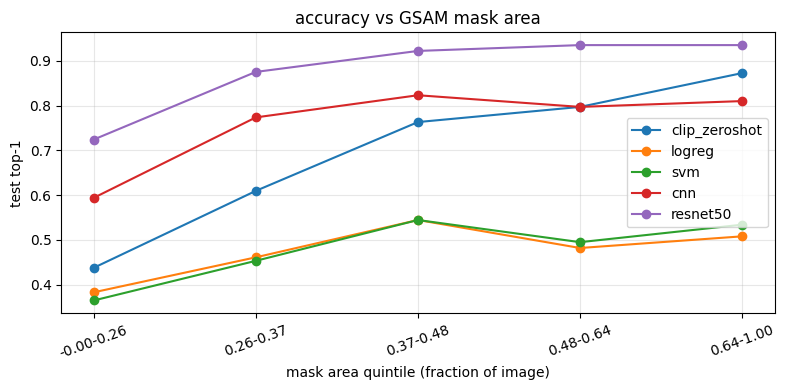

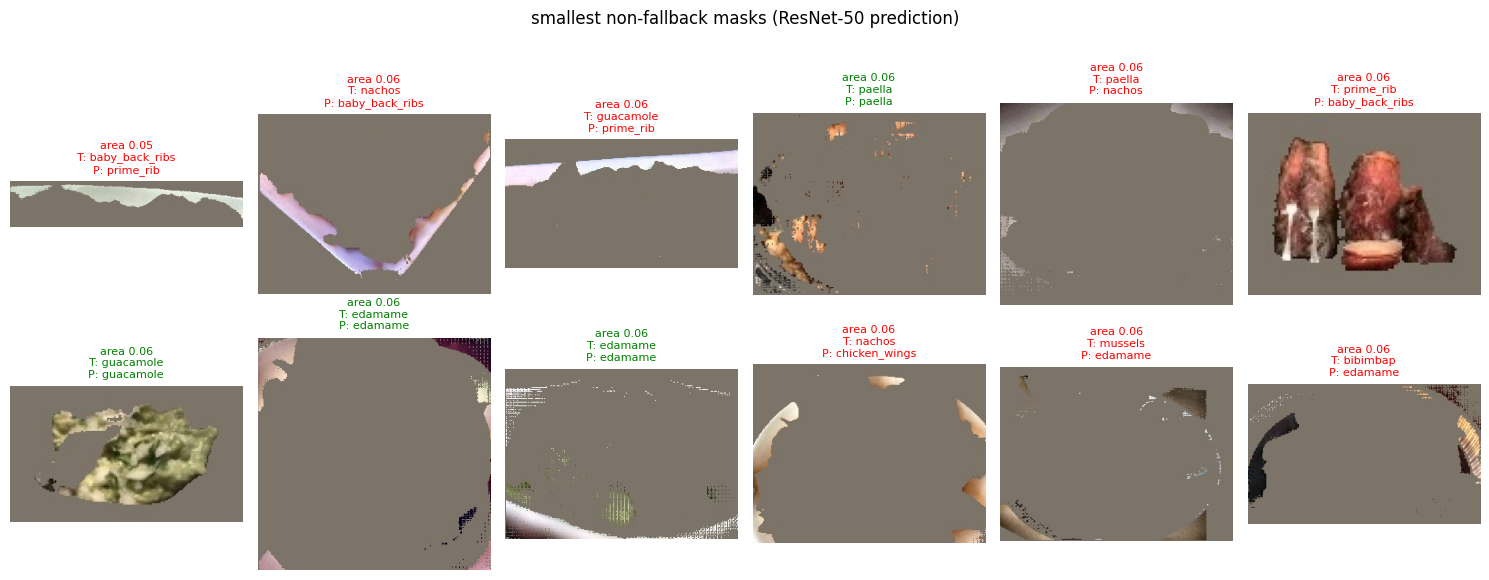

In [26]:
if HAS_GSAM:
    test_gs = splits["test"][["relpath"]].merge(gs, on="relpath", how="left")
    test_gs["area_bin"] = pd.qcut(test_gs.mask_area, 5, duplicates="drop")
    by_fb, by_area = {}, {}
    for m in RESULTS:
        pr = pd.read_csv(OUT / m / "predictions_test.csv")
        correct = (pr.y_true == pr.y_pred).values
        by_fb[m] = pd.Series(correct).groupby(test_gs.fallback.values).mean()
        by_area[m] = pd.Series(correct).groupby(test_gs.area_bin.values, observed=True).mean()
    fb_table = pd.DataFrame(by_fb).T.rename(columns={0: "segmented", 1: "fallback"})
    fb_table["n_fallback"] = int(test_gs.fallback.sum())
    display(fb_table)
    area_table = pd.DataFrame(by_area)
    area_table.index = [f"{iv.left:.2f}-{iv.right:.2f}" for iv in area_table.index]
    display(area_table)
    fig, ax = plt.subplots(figsize=(8, 4))
    for m in area_table.columns:
        ax.plot(range(len(area_table)), area_table[m], "o-", label=m)
    ax.set_xticks(range(len(area_table)), area_table.index, rotation=20); ax.legend()
    ax.set_xlabel("mask area quintile (fraction of image)"); ax.set_ylabel("test top-1"); ax.set_title("accuracy vs GSAM mask area")
    plt.tight_layout(); savefig(fig, "gsam_mask_area_accuracy"); plt.show()

    small = test_gs[test_gs.fallback == 0].nsmallest(12, "mask_area")
    pr = pd.read_csv(OUT / "resnet50" / "predictions_test.csv").set_index("relpath")
    fig, axes = plt.subplots(2, 6, figsize=(15, 6))
    for ax, (_, r) in zip(axes.ravel(), small.iterrows()):
        p = pr.loc[r.relpath]
        ax.imshow(Image.open(DATA_ROOT / DATASET / r.relpath))
        ax.set_title(f"area {r.mask_area:.2f}\nT: {p.label}\nP: {p.pred_label}", fontsize=8, color="green" if p.y_true == p.y_pred else "red")
        ax.axis("off")
    finish(fig, "smallest non-fallback masks (ResNet-50 prediction)", "gsam_smallest_masks")

mask_check,ok,suspect,bad,fallback,bad+suspect %
split,,,,,
train,4748,402,577,53,16.9
val,1581,126,196,27,16.7
test,1609,111,188,12,15.6


mask_check,ok,suspect,bad,fallback,bad %,bad+suspect %
label,,,,,,
edamame,707,51,189,16,19.6,24.9
nachos,742,69,146,6,15.2,22.3
chicken_wings,750,69,136,8,14.1,21.3
mussels,751,67,137,8,14.2,21.2
bibimbap,803,90,67,3,7.0,16.3
prime_rib,807,60,87,9,9.0,15.3
baby_back_ribs,812,64,78,9,8.1,14.7
guacamole,818,94,44,7,4.6,14.3
paella,824,54,75,10,7.8,13.4


,acc_ok,acc_suspect,acc_bad,acc_fallback,errors_from_bad+suspect
clip_zeroshot,0.772,0.423,0.191,0.917,0.370
logreg,0.512,0.351,0.250,0.250,0.212
svm,0.513,0.360,0.261,0.250,0.210
cnn,0.814,0.586,0.410,0.500,0.340
resnet50,0.932,0.757,0.500,0.750,0.517


n per group (test): {'ok': 1609, 'suspect': 111, 'bad': 188, 'fallback': 12}


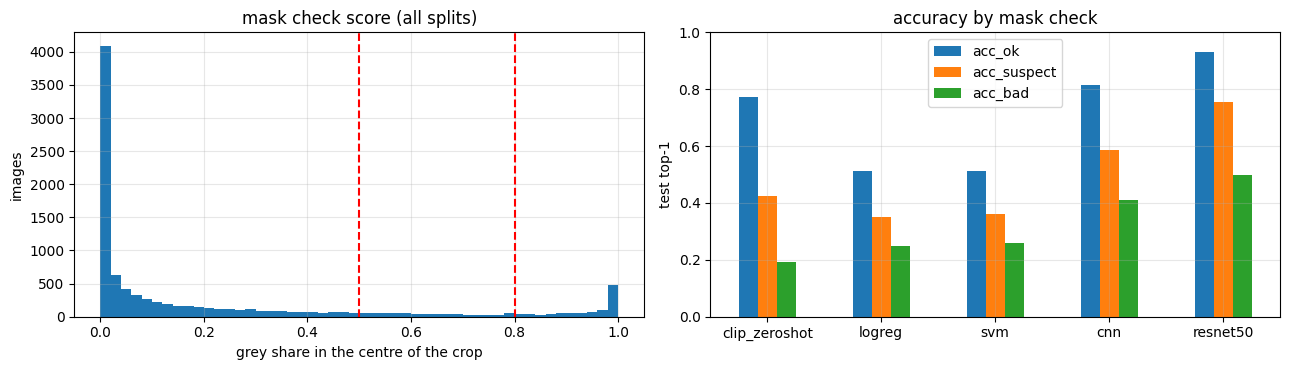

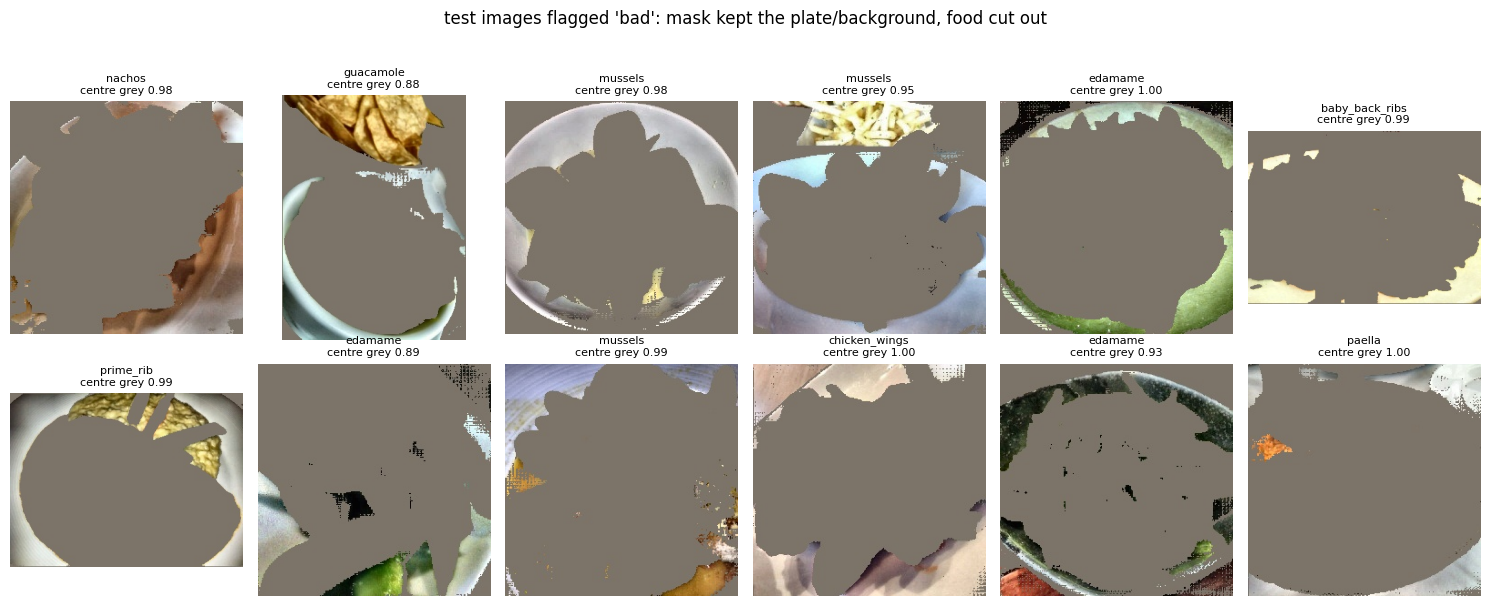

In [27]:
# 10.2 mask check: is the food in the centre of the crop, or did the mask keep the plate and cut the food out?
from joblib import Parallel, delayed
from scipy.ndimage import uniform_filter

MASK_OK_BELOW, MASK_BAD_FROM = 0.5, 0.8   # centre-grey thresholds, chosen by looking at samples (see the text above)


def grey_layout(path):
    """Share of flat grey fill in the centre (middle 50%) and on the border (outer 10%) of a GSAM image.
    Fill = close to PAD_FILL and locally flat; food is textured, so food that happens to be grey-brown is not counted."""
    a = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32)
    g = a.mean(axis=2)
    std = np.sqrt(np.clip(uniform_filter(g * g, 5) - uniform_filter(g, 5) ** 2, 0, None))
    m = (np.abs(a - np.array(PAD_FILL, dtype=np.float32)).max(axis=2) <= 10) & (std < 3.0)
    h, w = m.shape
    bh, bw = max(1, h // 10), max(1, w // 10)
    border = np.concatenate([m[:bh].ravel(), m[-bh:].ravel(), m[:, :bw].ravel(), m[:, -bw:].ravel()])
    return m[h // 4: h - h // 4, w // 4: w - w // 4].mean(), border.mean()


if HAS_GSAM:
    mc = df_all[["relpath", "path", "label", "split"]].merge(gs[["relpath", "mask_area", "fallback"]], on="relpath")
    mc[["grey_centre", "grey_border"]] = Parallel(n_jobs=-1, batch_size=64)(delayed(grey_layout)(p) for p in mc.path)
    mc["mask_check"] = np.select([mc.fallback == 1, mc.grey_centre >= MASK_BAD_FROM, mc.grey_centre >= MASK_OK_BELOW],
                                 ["fallback", "bad", "suspect"], "ok")
    mc.drop(columns="path").to_csv(OUT / "mask_check.csv", index=False)
    order = ["ok", "suspect", "bad", "fallback"]

    by_split = pd.crosstab(mc.split, mc.mask_check).reindex(index=["train", "val", "test"], columns=order, fill_value=0)
    by_split["bad+suspect %"] = (100 * (by_split.bad + by_split.suspect) / by_split[order].sum(axis=1)).round(1)
    display(by_split)
    by_cls = pd.crosstab(mc.label, mc.mask_check).reindex(columns=order, fill_value=0)
    by_cls["bad %"] = (100 * by_cls.bad / by_cls[order].sum(axis=1)).round(1)
    by_cls["bad+suspect %"] = (100 * (by_cls.bad + by_cls.suspect) / by_cls[order].sum(axis=1)).round(1)
    display(by_cls.sort_values("bad+suspect %", ascending=False))

    # accuracy of every model by mask check (test set)
    test_mc = splits["test"][["relpath"]].merge(mc, on="relpath", how="left")
    acc_rows = {}
    for m in RESULTS:
        pr = pd.read_csv(OUT / m / "predictions_test.csv")
        correct = pd.Series((pr.y_true == pr.y_pred).values)
        grp = correct.groupby(test_mc.mask_check.values)
        acc_rows[m] = {**{f"acc_{k}": grp.mean().get(k, np.nan) for k in order},
                       "errors_from_bad+suspect": float((~correct)[test_mc.mask_check.isin(["bad", "suspect"]).values].sum() / max(1, (~correct).sum()))}
    acc_table = pd.DataFrame(acc_rows).T
    display(acc_table.style.format("{:.3f}"))
    print("n per group (test):", test_mc.mask_check.value_counts().reindex(order, fill_value=0).to_dict())

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    axes[0].hist(mc[mc.fallback == 0].grey_centre, bins=50)
    for t in (MASK_OK_BELOW, MASK_BAD_FROM): axes[0].axvline(t, ls="--", c="red")
    axes[0].set_xlabel("grey share in the centre of the crop"); axes[0].set_ylabel("images"); axes[0].set_title("mask check score (all splits)")
    acc_table[[f"acc_{k}" for k in ("ok", "suspect", "bad")]].plot.bar(ax=axes[1], rot=0)
    axes[1].set_ylim(0, 1); axes[1].set_ylabel("test top-1"); axes[1].set_title("accuracy by mask check")
    plt.tight_layout(); savefig(fig, "gsam_mask_check"); plt.show()

    bad = mc[(mc.mask_check == "bad") & (mc.split == "test")]
    bad = bad.sample(min(12, len(bad)), random_state=SEED)
    fig, axes = plt.subplots(2, 6, figsize=(15, 6.2), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), bad.iterrows()):
        ax.imshow(Image.open(r.path)); ax.set_title(f"{r.label}\ncentre grey {r.grey_centre:.2f}", fontsize=8)
    finish(fig, "test images flagged 'bad': mask kept the plate/background, food cut out", "gsam_bad_masks")

In [28]:
# ==== save EVERY tried config (not only the chosen one) -> results/<dataset>/all_models/<name>/ ====
# Run after section 7. Same file format as save_final, so section 12 can reload any of them,
# e.g. load_model("all_models/cnn_d3") or predict_saved("all_models/svm_C10_g1").
# Already-saved folders are skipped, so re-running after a Colab disconnect only does what is missing.
ALL = OUT / "all_models"
ALL.mkdir(exist_ok=True)


def save_one(name, kind, get_model, arch, val_f1):
    if (ALL / name / "config.json").exists() and not RETRAIN:
        print(f"skip {name} (already saved)")
        return
    model = get_model()
    save_final(f"all_models/{name}", kind, model, arch)
    cfg_path = ALL / name / "config.json"
    cfg = json.loads(cfg_path.read_text())
    cfg["val_macro_f1"] = float(val_f1)                      # from the grid table (test is scored for the chosen model only)
    cfg_path.write_text(json.dumps(cfg, indent=2, default=str))
    del model


# CLIP: one per prompt template set (only the class text embeddings are stored, the CLIP weights come from Hugging Face)
for _, r in clip_grid.iterrows():
    save_one(f"clip_{r.templates.replace(' ', '_')}", "clip",
             lambda: CLIPZeroShot(clip, clip_text_embeddings(TEMPLATE_SETS[r.templates])),
             {"clip_id": CLIP_ID, "templates": TEMPLATE_SETS[r.templates]}, r.val_f1)

# LogReg / SVM: the sweep only kept the scores, so each config is refitted on train (same data, same result)
for _, r in lr_grid.iterrows():
    save_one(f"logreg_C{r.C:g}", "sklearn", lambda: make_logreg(C=float(r.C)).fit(X["train"], y_split["train"]),
             {"features": CLASSICAL_FEATURES, "C": float(r.C)}, r.val_f1)
for _, r in svm_grid.iterrows():
    save_one(f"svm_C{r.C:g}_g{r.gamma_mult:g}", "sklearn",
             lambda: make_svm(C=float(r.C), gamma_mult=float(r.gamma_mult)).fit(X["train"], y_split["train"]),
             {"features": CLASSICAL_FEATURES, "C": float(r.C), "gamma_mult": float(r.gamma_mult)}, r.val_f1)

# CNN / ResNet-50: fit() already kept the best-val-epoch weights of every config in checkpoints/, just repackage them
for _, r in cnn_grid.iterrows():
    arch = {"n_blocks": int(r.n_blocks), "base": int(r.base), "dropout": float(r.dropout)}
    save_one(r["name"], "cnn", lambda: load_trained(r.ckpt, lambda: SimpleCNN(**arch)), arch, r.val_f1)
for _, r in rn_grid.iterrows():
    save_one(r["name"], "resnet50", lambda: load_trained(r.ckpt, lambda: make_resnet50(r["unfreeze"])),
             {"unfreeze": r["unfreeze"]}, r.val_f1)

saved = pd.DataFrame([json.loads(p.read_text()) for p in sorted(ALL.glob("*/config.json"))])
saved["size_MB"] = [round((ALL / m.split("/")[-1] / f).stat().st_size / 1e6, 1) for m, f in zip(saved.model, saved.file)]
display(saved[["model", "kind", "file", "val_macro_f1", "size_MB"]].sort_values("val_macro_f1", ascending=False))

saved /content/drive/MyDrive/food_classify/results/03_denoise_clahe_gsam/all_models/clip_classname/model.pt (0.0 MB) + config.json
saved /content/drive/MyDrive/food_classify/results/03_denoise_clahe_gsam/all_models/clip_a_photo_of/model.pt (0.0 MB) + config.json
saved /content/drive/MyDrive/food_classify/results/03_denoise_clahe_gsam/all_models/clip_food_photo/model.pt (0.0 MB) + config.json
saved /content/drive/MyDrive/food_classify/results/03_denoise_clahe_gsam/all_models/clip_ensemble/model.pt (0.0 MB) + config.json
saved /content/drive/MyDrive/food_classify/results/03_denoise_clahe_gsam/all_models/logreg_C0.0001/model.joblib (0.2 MB) + config.json
saved /content/drive/MyDrive/food_classify/results/03_denoise_clahe_gsam/all_models/logreg_C0.001/model.joblib (0.2 MB) + config.json
saved /content/drive/MyDrive/food_classify/results/03_denoise_clahe_gsam/all_models/logreg_C0.01/model.joblib (0.2 MB) + config.json
saved /content/drive/MyDrive/food_classify/results/03_denoise_clahe_gsam/

,model,kind,file,val_macro_f1,size_MB
14,all_models/resnet50_all,resnet50,model.pt,0.8662,94.4
16,all_models/resnet50_layer4,resnet50,model.pt,0.8595,94.4
15,all_models/resnet50_fc,resnet50,model.pt,0.7967,94.4
6,all_models/cnn_d5,cnn,model.pt,0.7515,18.9
4,all_models/cnn_d3,cnn,model.pt,0.6985,1.2
2,all_models/clip_ensemble,clip,model.pt,0.6944,0.0
0,all_models/clip_a_photo_of,clip,model.pt,0.6876,0.0
3,all_models/clip_food_photo,clip,model.pt,0.6866,0.0
1,all_models/clip_classname,clip,model.pt,0.6569,0.0
5,all_models/cnn_d4,cnn,model.pt,0.6195,4.7


## 11. Cross-dataset comparison: does segmentation help?
Runs once the 01 / 02 / 03 results are all in `results/<dataset>/<model>/predictions_test.csv`
(run this notebook with each `DATASET`, or teammates copy their folders in using the same file format). Every dataset has the same test images, so the tests are **paired**:
- **McNemar exact test**: among the images only one of the two datasets classifies correctly, is the split uneven? p < 0.05 = a real difference in accuracy.
- **Bootstrap 95% CI** of the macro-F1 difference (1,000 resamples of the test images). If the CI excludes 0, the difference is reliable.

With about 1,920 test images, accuracy gaps under roughly 2 points are usually noise. 3 pairs × 5 models is 15 tests, so a single p ≈ 0.04 is weak evidence.

dataset,03_denoise_clahe_gsam
model,
clip_zeroshot,0.699
cnn,0.759
logreg,0.475
resnet50,0.878
svm,0.476


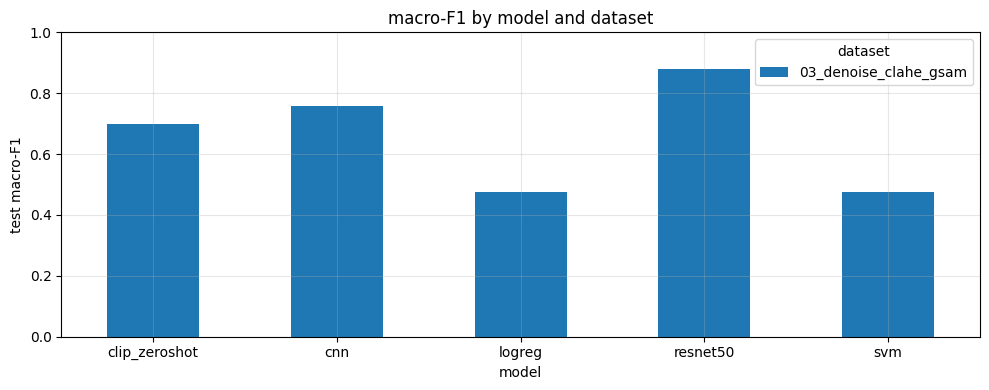

only ['03_denoise_clahe_gsam'] found so far; run the other datasets to compare


In [29]:
from scipy.stats import binomtest

DATASETS = ["01_original", "02_denoise_clahe", "03_denoise_clahe_gsam"]
PAIRS = [("01_original", "02_denoise_clahe"), ("02_denoise_clahe", "03_denoise_clahe_gsam"), ("01_original", "03_denoise_clahe_gsam")]
MODELS = ["clip_zeroshot", "logreg", "svm", "cnn", "resnet50"]


def load_preds(ds, model):
    p = OUT.parent / ds / model / "predictions_test.csv"
    return pd.read_csv(p).set_index("relpath").sort_index() if p.exists() else None


rows, per_ds = [], []
rng = np.random.default_rng(SEED)
for model in MODELS:
    preds = {ds: load_preds(ds, model) for ds in DATASETS}
    for ds, pr in preds.items():
        if pr is not None:
            per_ds.append({"model": model, "dataset": ds, "top1": (pr.y_true == pr.y_pred).mean(),
                           "macro_f1": f1_score(pr.y_true, pr.y_pred, average="macro")})
    for a, b in PAIRS:
        pa, pb = preds[a], preds[b]
        if pa is None or pb is None:
            continue
        assert pa.index.equals(pb.index), f"{a} and {b} have different test images"
        y, ya, yb = pa.y_true.values, pa.y_pred.values, pb.y_pred.values
        ca, cb = ya == y, yb == y
        n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
        p_mc = binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
        boot = []
        for _ in range(1000):
            i = rng.integers(0, len(y), len(y))
            boot.append(f1_score(y[i], yb[i], average="macro") - f1_score(y[i], ya[i], average="macro"))
        rows.append({"model": model, "A": a, "B": b, "acc_A": ca.mean(), "acc_B": cb.mean(), "delta_acc": cb.mean() - ca.mean(),
                     "delta_macro_f1": f1_score(y, yb, average="macro") - f1_score(y, ya, average="macro"),
                     "f1_ci_low": np.percentile(boot, 2.5), "f1_ci_high": np.percentile(boot, 97.5),
                     "only_A_right": n01, "only_B_right": n10, "mcnemar_p": p_mc})

if per_ds:
    pivot = pd.DataFrame(per_ds).pivot(index="model", columns="dataset", values="macro_f1")
    display(pivot.style.format("{:.3f}").background_gradient(cmap="Blues", axis=1))
    fig, ax = plt.subplots(figsize=(10, 4))
    pivot.reindex(columns=[d for d in DATASETS if d in pivot.columns]).plot.bar(ax=ax, rot=0)
    ax.set_ylabel("test macro-F1"); ax.set_ylim(0, 1); ax.set_title("macro-F1 by model and dataset")
    plt.tight_layout(); savefig(fig, "cross_dataset"); plt.show()
if rows:
    paired = pd.DataFrame(rows)
    display(paired.style.format({c: "{:.3f}" for c in paired.columns if c not in ("model", "A", "B", "only_A_right", "only_B_right")}))
    paired.to_csv(OUT.parent / "paired_tests.csv", index=False)
else:
    print("only", sorted({r['dataset'] for r in per_ds}), "found so far; run the other datasets to compare")

## 12. Reload the saved models
Sections 4–7 already score the test set with the model each one just trained, still in memory. This section is separate: it rebuilds each final model **from its saved file**,
so it works in a fresh kernel, on another machine, or in a teammate's notebook. Run sections 0–3 first (settings, paths, imports, data, transforms, metric functions), then this section.
It does not need the training sections: the model classes and feature function are defined here again (identical to sections 5–7).

- `load_model(name, dataset)` reads `results/<dataset>/<name>/config.json` and rebuilds the model.
- **12.1** `predict_saved(name)` scores the whole test set with the reloaded model and checks the numbers against `metrics.json` from training. If they match, the saved file is correct.
- **12.2** `classify(path, name)` gives the top-k classes for one image.

Every model expects the same preprocessing as its dataset. A model trained on 03 expects a denoised, CLAHE'd, GSAM-cropped image, so an outside photo
should go through the team's 02/03 pipeline first. The example uses a test image from the dataset, which is already preprocessed.

In [30]:
import joblib
import cv2
from skimage.feature import hog, local_binary_pattern
from transformers import CLIPModel


class SimpleCNN(nn.Module):
    def __init__(self, n_blocks=4, base=32, dropout=0.3, n_classes=K):
        super().__init__()
        layers, c_in = [], 3
        for i in range(n_blocks):
            c = base * 2 ** i
            layers += [nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                       nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                       nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def make_resnet50(unfreeze, pretrained=True):
    m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
    m.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.fc.in_features, K))
    for p in m.parameters():
        p.requires_grad_(False)
    for part in {"fc": [m.fc], "layer4": [m.layer4, m.fc], "all": [m]}[unfreeze]:
        for p in part.parameters():
            p.requires_grad_(True)
    return m


class CLIPZeroShot(nn.Module):
    def __init__(self, clip, text_emb):
        super().__init__()
        self.clip = clip
        self.register_buffer("text_emb", text_emb)

    def forward(self, x):
        f = self.clip.visual_projection(self.clip.vision_model(pixel_values=x).pooler_output)
        return self.clip.logit_scale.exp() * F.normalize(f, dim=-1) @ self.text_emb.T


def handcrafted(path):
    rgb = np.asarray(pad_to_square(Image.open(path).convert("RGB")).resize((128, 128), Image.BILINEAR))
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    color = cv2.calcHist([hsv], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256]).ravel()
    color /= color.sum() + 1e-8
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    shape = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm="L2-Hys")
    texture = []
    for p, r in ((8, 1), (16, 2)):
        h, _ = np.histogram(local_binary_pattern(gray, p, r, method="uniform"), bins=p + 2, range=(0, p + 2))
        texture.append(h / h.sum())
    return np.concatenate([color, shape, *texture]).astype(np.float32)


_LOADED = {}   # (dataset, name) -> (model, config), so repeated calls don't reload from disk


def load_model(name, dataset=DATASET):
    """Rebuild a saved final model from results/<dataset>/<name>/. Returns (model, config)."""
    if (dataset, name) in _LOADED:
        return _LOADED[(dataset, name)]
    d = OUT.parent / dataset / name
    assert (d / "config.json").exists(), f"no saved model in {d}: run that model's section first"
    with open(d / "config.json") as f:
        cfg = json.load(f)
    assert cfg["classes"] == CLASSES, "saved model was trained on different classes"
    if cfg["kind"] == "sklearn":
        model = joblib.load(d / cfg["file"])
    else:
        ck = torch.load(d / cfg["file"], map_location="cpu")
        if cfg["kind"] == "cnn":
            model = SimpleCNN(**ck["arch"])
            model.load_state_dict(ck["state_dict"])
        elif cfg["kind"] == "resnet50":
            model = make_resnet50(ck["arch"]["unfreeze"], pretrained=False)
            model.load_state_dict(ck["state_dict"])
        elif cfg["kind"] == "clip":
            clip_m = CLIPModel.from_pretrained(ck["arch"]["clip_id"])
            model = CLIPZeroShot(clip_m, ck["text_emb"])
        model = model.to(DEVICE).eval()
    _LOADED[(dataset, name)] = (model, cfg)
    print(f"loaded {name} ({dataset}): val macro-F1 {cfg['val_macro_f1']}, test macro-F1 {cfg['test_macro_f1']}")
    return model, cfg


@torch.no_grad()
def resnet_embedding_one(img):
    if "embedder" not in _LOADED:
        m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Identity()
        _LOADED["embedder"] = m.to(DEVICE).eval()
    return _LOADED["embedder"](eval_tf(img)[None].to(DEVICE)).cpu().numpy()


@torch.no_grad()
def predict_saved(name, split="test"):
    """Scores of a reloaded model on a whole split of this notebook's dataset -> (y, scores)."""
    model, cfg = load_model(name, DATASET)
    frame = splits[split]
    if cfg["kind"] == "sklearn":
        if cfg["arch"]["features"] == "handcrafted":
            from joblib import Parallel, delayed
            feats = np.stack(Parallel(n_jobs=-1, batch_size=32)(delayed(handcrafted)(p) for p in frame.path))
        else:
            feats = np.concatenate([resnet_embedding_one(Image.open(p).convert("RGB")) for p in frame.path])
        scores = model.predict_proba(feats) if hasattr(model, "predict_proba") else model.decision_function(feats)
    else:
        tf = clip_tf if cfg["kind"] == "clip" else eval_tf
        scores = np.concatenate([model(x.to(DEVICE)).float().softmax(1).cpu().numpy() for x, _ in make_loader(split, tf)])
    return frame.y.values, scores


@torch.no_grad()
def classify(path, name, dataset=DATASET, k=3, show=True):
    """Top-k prediction of one saved model for one image file."""
    model, cfg = load_model(name, dataset)
    img = Image.open(path).convert("RGB")
    if cfg["kind"] == "sklearn":
        feats = handcrafted(path)[None] if cfg["arch"]["features"] == "handcrafted" else resnet_embedding_one(img)
        scores = model.predict_proba(feats)[0] if hasattr(model, "predict_proba") else model.decision_function(feats)[0]
    else:
        tf = clip_tf if cfg["kind"] == "clip" else eval_tf
        scores = model(tf(img)[None].to(DEVICE)).float().softmax(1)[0].cpu().numpy()
    top = np.argsort(-scores)[:k]
    result = [(CLASSES[i], float(scores[i])) for i in top]
    if show:
        fig, ax = plt.subplots(figsize=(3.2, 3.6))
        ax.imshow(img); ax.axis("off")
        ax.set_title(f"{name} ({dataset[:2]})\n" + "\n".join(f"{c}: {v:.2f}" for c, v in result), fontsize=9)
        plt.show()
    return result

In [31]:
# 12.1 whole test set from the saved files, compared with the numbers recorded at training time
rows = []
for name in ["clip_zeroshot", "logreg", "svm", "cnn", "resnet50"]:
    if not (OUT / name / "config.json").exists():
        print(f"{name}: not saved yet"); continue
    y, sc = predict_saved(name, "test")
    m, _ = compute_metrics(y, sc)
    with open(OUT / name / "metrics.json") as f:
        trained = json.load(f)["test"]
    rows.append({"model": name, **{k: m[k] for k in ("top1", "top3", "top5", "macro_f1", "mAP")},
                 "macro_f1_at_training": trained["macro_f1"],
                 "match": abs(m["macro_f1"] - trained["macro_f1"]) < 1e-3})
if rows:
    reloaded = pd.DataFrame(rows).set_index("model")
    display(reloaded)
    if not reloaded.match.all():
        print("a reloaded model differs from its training-time result: check that the dataset and settings are the same as when it was saved")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

loaded clip_zeroshot (03_denoise_clahe_gsam): val macro-F1 0.6943592208773366, test macro-F1 0.699322034263175
loaded logreg (03_denoise_clahe_gsam): val macro-F1 0.47897231042179866, test macro-F1 0.4747654868523316
loaded svm (03_denoise_clahe_gsam): val macro-F1 0.5074097316518664, test macro-F1 0.4759537908197218
loaded cnn (03_denoise_clahe_gsam): val macro-F1 0.7514593690537346, test macro-F1 0.7586174276202614
loaded resnet50 (03_denoise_clahe_gsam): val macro-F1 0.8662160992794057, test macro-F1 0.8781718763968452


,top1,top3,top5,macro_f1,mAP,macro_f1_at_training,match
model,,,,,,,
clip_zeroshot,0.6958,0.8547,0.9151,0.6993,0.8111,0.6993,True
logreg,0.4755,0.7625,0.8818,0.4748,0.4728,0.4748,True
svm,0.4781,0.7703,0.8927,0.4760,0.4926,0.4760,True
cnn,0.7594,0.9141,0.9651,0.7586,0.8441,0.7586,True
resnet50,0.8786,0.9609,0.9828,0.8787,0.9404,0.8782,True


true label: baby_back_ribs | test/baby_back_ribs/915852.jpg
clip_zeroshot  [('guacamole', 0.2792139947414398), ('nachos', 0.2608444392681122), ('chicken_wings', 0.20800261199474335)]
logreg         [('prime_rib', 0.23643206523231514), ('baby_back_ribs', 0.21364434845967167), ('bibimbap', 0.12824092342827811)]
svm            [('prime_rib', 9.28888367116303), ('baby_back_ribs', 8.273536231423792), ('mussels', 7.249727028981116)]
cnn            [('baby_back_ribs', 0.8843103051185608), ('nachos', 0.025072792544960976), ('paella', 0.018534531816840172)]
resnet50       [('baby_back_ribs', 0.848527729511261), ('prime_rib', 0.03866107016801834), ('edamame', 0.018288416787981987)]


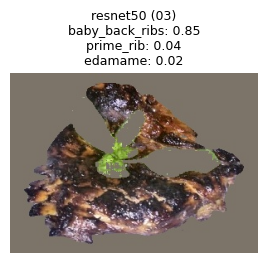

In [32]:
# 12.2 one image: every saved model on the same test image (swap in any image path)
example = splits["test"].sample(1, random_state=SEED).iloc[0]
print("true label:", example.label, "|", example.relpath)
for name in ["clip_zeroshot", "logreg", "svm", "cnn", "resnet50"]:
    if (OUT / name / "config.json").exists():
        print(f"{name:14s}", classify(example.path, name, show=False))
    else:
        print(f"{name:14s} not saved yet")
if (OUT / "resnet50" / "config.json").exists():
    classify(example.path, "resnet50")

## 13. Checklist for the report
- [ ] Data: same manifest hash as the team, balanced counts, cleaning summary (`removed.csv`), cross-split duplicate check
- [ ] Per model: chosen hyper-parameters + the train/val graph that justifies them; final model saved (`model.pt` / `model.joblib` + `config.json`)
- [ ] Test table: top-1/3/5, macro P/R/F1, mAP; per-class table; confusion matrix + most-confused pairs
- [ ] Correct / wrong examples and Grad-CAM (fixed images compared across 01/02/03)
- [ ] GSAM: fallback vs segmented accuracy, accuracy vs mask area, mask check (share of bad / suspect masks, accuracy on them, examples)
- [ ] Cross-dataset: macro-F1 per model × dataset, paired McNemar + bootstrap CI
- [ ] Limits: 1 seed (re-run CNN/ResNet with 2–3 more seeds if time allows), label noise in Food-101, 12 fallback test images only

clip_classname         val F1 0.657 | test F1 0.676
clip_a_photo_of        val F1 0.688 | test F1 0.692
clip_food_photo        val F1 0.687 | test F1 0.703
clip_ensemble          val F1 0.694 | test F1 0.699
logreg_C0.0001         val F1 0.442 | test F1 0.425
logreg_C0.001          val F1 0.479 | test F1 0.475
logreg_C0.01           val F1 0.466 | test F1 0.455
logreg_C0.1            val F1 0.440 | test F1 0.433
logreg_C1              val F1 0.427 | test F1 0.422
logreg_C10             val F1 0.421 | test F1 0.422
logreg_C100            val F1 0.416 | test F1 0.411
svm_C0.1_g0.3          val F1 0.305 | test F1 0.311
svm_C1_g0.3            val F1 0.461 | test F1 0.462
svm_C10_g0.3           val F1 0.495 | test F1 0.481
svm_C100_g0.3          val F1 0.477 | test F1 0.472
svm_C1000_g0.3         val F1 0.477 | test F1 0.472
svm_C0.1_g1            val F1 0.343 | test F1 0.331
svm_C1_g1              val F1 0.481 | test F1 0.474
svm_C10_g1             val F1 0.507 | test F1 0.476
svm_C100_g1 

,family,model,chosen,val_macro_f1,test_top1,test_top3,test_top5,test_macro_precision,test_macro_recall,test_macro_f1,test_mAP
0,CLIP zero-shot,clip_classname,False,0.657,0.673,0.829,0.902,0.745,0.673,0.676,0.796
1,CLIP zero-shot,clip_a_photo_of,False,0.688,0.689,0.842,0.911,0.737,0.689,0.692,0.807
2,CLIP zero-shot,clip_food_photo,False,0.687,0.698,0.849,0.922,0.732,0.698,0.703,0.811
3,CLIP zero-shot,clip_ensemble,True,0.694,0.696,0.855,0.915,0.733,0.696,0.699,0.811
4,LogReg,logreg_C0.0001,False,0.442,0.435,0.719,0.868,0.428,0.435,0.425,0.430
5,LogReg,logreg_C0.001,True,0.479,0.476,0.762,0.882,0.476,0.476,0.475,0.473
6,LogReg,logreg_C0.01,False,0.466,0.453,0.750,0.880,0.458,0.453,0.455,0.459
7,LogReg,logreg_C0.1,False,0.440,0.429,0.724,0.865,0.438,0.429,0.433,0.426
8,LogReg,logreg_C1,False,0.427,0.418,0.711,0.856,0.428,0.418,0.422,0.410
9,LogReg,logreg_C10,False,0.421,0.418,0.709,0.858,0.428,0.418,0.422,0.405


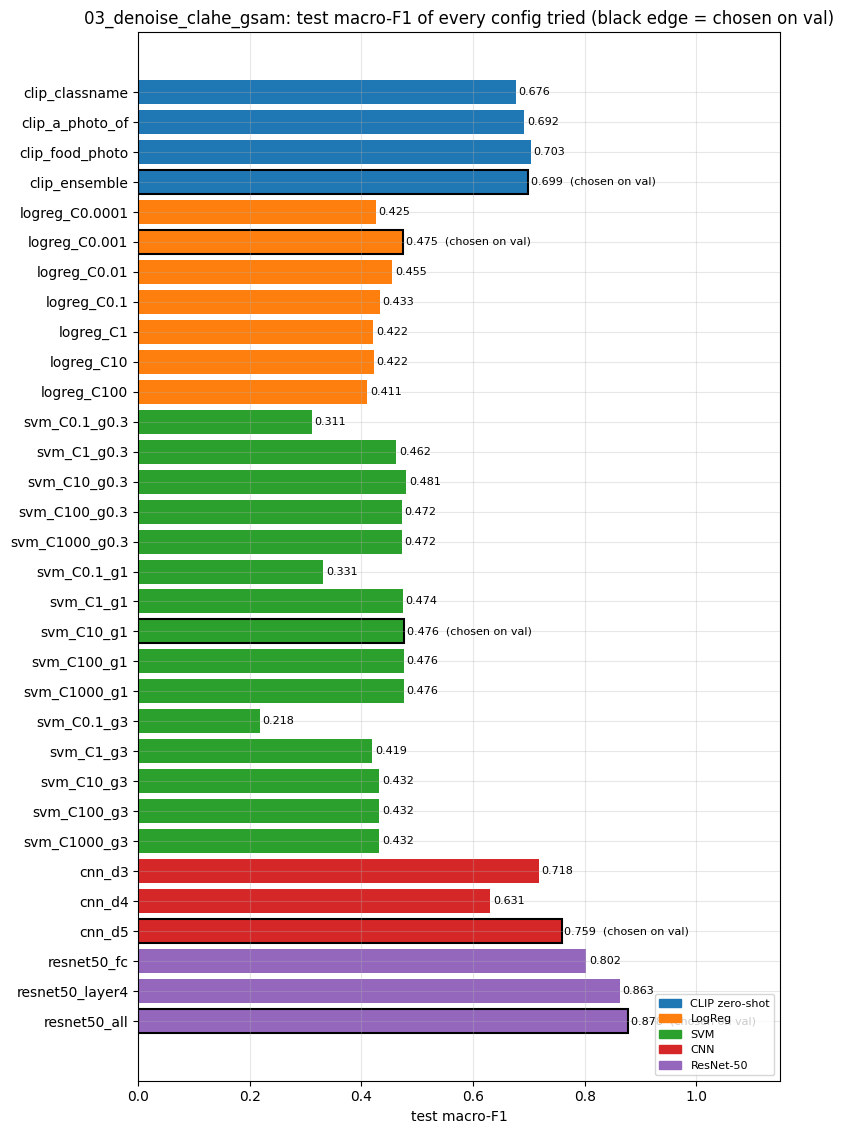

In [33]:
# ==== val + test scores of EVERY config tried (same session; only the table, CSV and plot are written) ====
# Only the chosen models are still in memory, so the others are rebuilt: CNN / ResNet-50 from checkpoints/
# (fit() writes one per config), LogReg / SVM from all_models/ if saved there, else refitted on train.
# The choice is still made on val only ("chosen" column); the test scores of the others are for the report, not for picking.
import joblib

all_rows = []


@torch.no_grad()
def score_one(family, name, kind, model, chosen):
    res = {}
    for sp in ("val", "test"):
        if kind == "clip":
            y, s = y_split[sp], (clip.logit_scale.exp() * img_emb[sp] @ model.T).softmax(1).cpu().numpy()
        elif kind == "sklearn":
            y, s = y_split[sp], model.predict_proba(X[sp]) if hasattr(model, "predict_proba") else model.decision_function(X[sp])
        else:
            y, s = predict(model, sp)
        res[sp] = compute_metrics(y, s)[0]
    all_rows.append({"family": family, "model": name, "chosen": chosen, "val_macro_f1": res["val"]["macro_f1"],
                     **{f"test_{k}": v for k, v in res["test"].items() if k != "n"}})
    print(f"{name:22s} val F1 {res['val']['macro_f1']:.3f} | test F1 {res['test']['macro_f1']:.3f}")


def sk_model(name, build):
    f = OUT / "all_models" / name / "model.joblib"
    return joblib.load(f) if f.exists() else build().fit(X["train"], y_split["train"])


for i, r in clip_grid.iterrows():
    score_one("CLIP zero-shot", f"clip_{r.templates.replace(' ', '_')}", "clip",
              clip_text_embeddings(TEMPLATE_SETS[r.templates]), i == clip_grid.val_f1.idxmax())
for i, r in lr_grid.iterrows():
    score_one("LogReg", f"logreg_C{r.C:g}", "sklearn",
              sk_model(f"logreg_C{r.C:g}", lambda: make_logreg(C=float(r.C))), i == lr_grid.val_f1.idxmax())
for i, r in svm_grid.iterrows():
    score_one("SVM", f"svm_C{r.C:g}_g{r.gamma_mult:g}", "sklearn",
              sk_model(f"svm_C{r.C:g}_g{r.gamma_mult:g}", lambda: make_svm(C=float(r.C), gamma_mult=float(r.gamma_mult))),
              i == svm_grid.val_f1.idxmax())
for i, r in cnn_grid.iterrows():
    arch = {"n_blocks": int(r.n_blocks), "base": int(r.base), "dropout": float(r.dropout)}
    score_one("CNN", r["name"], "cnn", load_trained(r.ckpt, lambda: SimpleCNN(**arch)), i == cnn_grid.val_f1.idxmax())
for i, r in rn_grid.iterrows():
    score_one("ResNet-50", r["name"], "resnet50", load_trained(r.ckpt, lambda: make_resnet50(r["unfreeze"])),
              i == rn_grid.val_f1.idxmax())

all_models = pd.DataFrame(all_rows)
all_models.to_csv(OUT / "all_models_test.csv", index=False)
num = all_models.columns[3:]
display(all_models.style.format({c: "{:.3f}" for c in num}).background_gradient(cmap="Blues", subset=list(num))
        .apply(lambda r: ["font-weight: bold" if r.chosen else ""] * len(r), axis=1))

fig, ax = plt.subplots(figsize=(8, 0.32 * len(all_models) + 1.2))
fam = {f: f"C{j}" for j, f in enumerate(all_models.family.unique())}
ax.barh(all_models.model, all_models.test_macro_f1, color=[fam[f] for f in all_models.family],
        edgecolor=["black" if c else "none" for c in all_models.chosen], linewidth=1.5)
for y, (v, c) in enumerate(zip(all_models.test_macro_f1, all_models.chosen)):
    ax.text(v + 0.005, y, f"{v:.3f}" + ("  (chosen on val)" if c else ""), va="center", fontsize=8)
ax.invert_yaxis(); ax.set_xlim(0, 1.15); ax.set_xlabel("test macro-F1")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in fam.values()], labels=list(fam), fontsize=8, loc="lower right")
ax.set_title(f"{DATASET}: test macro-F1 of every config tried (black edge = chosen on val)")
plt.tight_layout(); savefig(fig, "all_models_test"); plt.show()